# Commercial Vehicle Reliability & Failure Pattern Analysis

----------

## Project Overview

This project analyses MOT test data to identify vehicle reliability patterns and common failure factors in commercial vehicles. The analysis focuses on vehicle age, mileage, vehicle characteristics, test results, and recorded defects to understand how failure rates vary across different vehicle conditions.

## Problem Statement

Vehicle failures are often analysed based on individual factors such as vehicle age, mileage, or failure type. However, failure risk can be influenced by the combination of vehicle age, total kilometres travelled, vehicle type, previous test history, and previous defects. This project aims to analyse these factors together to identify hidden vehicle failure patterns and understand how failure risk changes across different vehicle conditions.

## Project Objective

- Analyse vehicle failure patterns using MOT test data.
- Identify how failure rates vary with vehicle age and mileage.
- Analyse failure patterns across vehicle characteristics such as make, fuel type, vehicle class, and engine capacity.
- Identify common vehicle defects and defect categories.
- Understand the combined effect of vehicle age and mileage on failure rates.
- Generate insights that can support preventive maintenance planning.

## Dataset Description

The project uses the UK DVSA Anonymised MOT Tests and Results dataset. The dataset contains MOT test records with information such as vehicle details, test results, mileage, vehicle class, fuel type, engine capacity, and test dates. A separate MOT failure item dataset is used to analyse specific vehicle defects and failure patterns.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Exploratory Data Analysis

The dataset is analysed to understand vehicle test results, vehicle characteristics, mileage, age, and failure patterns. The analysis begins with basic data understanding and cleaning, followed by individual factor analysis and combined factor analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

chunksize = 500_000
total_rows = 0

for chunk in pd.read_csv(file_path, chunksize=chunksize):
    total_rows += len(chunk)

print("Total rows processed:", total_rows)

Total rows processed: 43441151


In [7]:
import pandas as pd

file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

chunksize = 500_000

total_rows = 0
missing_values = None
duplicate_rows = 0

for chunk in pd.read_csv(file_path, chunksize=chunksize):

    total_rows += len(chunk)

    if missing_values is None:
        missing_values = pd.Series(0, index=chunk.columns, dtype="int64")

    missing_values += chunk.isnull().sum()

    duplicate_rows += chunk.duplicated().sum()

print("Total rows:", total_rows)

print("\nMissing values:")
print(missing_values[missing_values > 0])

print("\nExact duplicate rows within each chunk:", duplicate_rows)

Total rows: 43441151

Missing values:
test_mileage         351981
make                      1
model                    27
cylinder_capacity    519008
first_use_date           57
vehicle_age              57
vehicle_age_group       491
mileage_group        351981
dtype: int64

Exact duplicate rows within each chunk: 0


In [9]:
import pandas as pd

# Define the path of the cleaned full-year 2024 dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Set the number of rows to process in each batch to avoid MemoryError
chunksize = 500_000

# Initialize counters for the full-year analysis
total_rows = 0
valid_outcomes = 0
failures = 0

# Store test result counts across all batches
outcome_counts = {}

# Read the complete dataset in batches instead of loading it into memory at once
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Count the total number of records processed
    total_rows += len(chunk)

    # Count each test result category in the current batch
    counts = chunk["test_result"].value_counts()

    # Accumulate test result counts across all batches
    for result, count in counts.items():
        outcome_counts[result] = outcome_counts.get(result, 0) + int(count)

    # Select valid outcomes: Pass (P), Fail (F), and PRS
    valid = chunk["test_result"].isin(["P", "F", "PRS"])

    # Count valid outcomes for the overall failure rate denominator
    valid_outcomes += int(valid.sum())

    # Count failed tests in the current batch
    failures += int((chunk["test_result"] == "F").sum())

# Display the total number of records processed
print("Total rows:", total_rows)

# Display the frequency of each test result category
print("\nTest result counts:")
print(pd.Series(outcome_counts).sort_index())

# Display the total number of valid outcomes
print("\nValid outcome denominator (P + F + PRS):", valid_outcomes)

# Display the total number of failed tests
print("Total failures:", failures)

# Calculate and display the overall observed failure rate
if valid_outcomes > 0:
    failure_rate = (failures / valid_outcomes) * 100
    print(f"Overall observed failure rate: {failure_rate:.2f}%")
else:
    print("Failure rate cannot be calculated because no valid outcomes were found.")

Total rows: 43441151

Test result counts:
ABA         29207
ABR        241425
ABRVE          21
F         8145625
P        33041072
PRS       1983801
dtype: int64

Valid outcome denominator (P + F + PRS): 43170498
Total failures: 8145625
Overall observed failure rate: 18.87%


In [10]:
import pandas as pd

# Define the cleaned dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Set the number of rows to process per batch
chunksize = 500_000

# Initialize counters for each vehicle age group
age_group_counts = {}

# Process the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid test outcomes for failure rate calculation
    valid = chunk[chunk["test_result"].isin(["P", "F", "PRS"])].copy()

    # Remove records with missing vehicle age groups
    valid = valid.dropna(subset=["vehicle_age_group"])

    # Count total valid tests and failed tests for each age group
    for age_group, group in valid.groupby("vehicle_age_group"):

        # Initialize counters for a new age group
        if age_group not in age_group_counts:
            age_group_counts[age_group] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate the number of valid tests
        age_group_counts[age_group]["total_tests"] += len(group)

        # Accumulate the number of failed tests
        age_group_counts[age_group]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert the accumulated results into a DataFrame
age_results = pd.DataFrame.from_dict(age_group_counts, orient="index")

# Calculate the failure rate percentage for each age group
age_results["failure_rate_%"] = (
    age_results["failed_tests"] / age_results["total_tests"] * 100
)

# Sort age groups for easier interpretation
age_results = age_results.sort_index()

# Display the full-year age-group failure analysis
print("Full-Year 2024 Vehicle Age Group Failure Analysis")
display(age_results.round(2))

Full-Year 2024 Vehicle Age Group Failure Analysis


,total_tests,failed_tests,failure_rate_%
0-3,1810317,158071,8.73
10-15,11780571,2730693,23.18
15+,9168127,2371244,25.86
3-5,4753862,469962,9.89
5-8,9202149,1248926,13.57
8-10,6454990,1166700,18.07


In [18]:
import pandas as pd

# Define the cleaned full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Process 500,000 rows at a time to reduce memory usage
chunksize = 500_000

# Initialize counters for each mileage group
mileage_group_counts = {}

# Read and analyse the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid outcomes for failure-rate calculation
    valid = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
    ].copy()

    # Exclude records with missing mileage groups
    valid = valid.dropna(subset=["mileage_group"])

    # Calculate total tests and failures for each mileage group
    for mileage_group, group in valid.groupby("mileage_group"):

        # Create counters when a mileage group appears for the first time
        if mileage_group not in mileage_group_counts:
            mileage_group_counts[mileage_group] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate valid test counts
        mileage_group_counts[mileage_group]["total_tests"] += len(group)

        # Accumulate failed test counts
        mileage_group_counts[mileage_group]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert accumulated results into a DataFrame
mileage_results = pd.DataFrame.from_dict(
    mileage_group_counts,
    orient="index"
)

# Calculate the observed failure rate for each mileage group
mileage_results["failure_rate_%"] = (
    mileage_results["failed_tests"]
    / mileage_results["total_tests"]
    * 100
)

# Display results ordered by mileage group
display(mileage_results.round(2))

,total_tests,failed_tests,failure_rate_%
0-20k,3197572,207178,6.48
100-150k,8385175,2174695,25.93
150-200k,2457803,661888,26.93
20-50k,11064743,1346705,12.17
200k+,789235,204249,25.88
50-100k,17162547,3516681,20.49


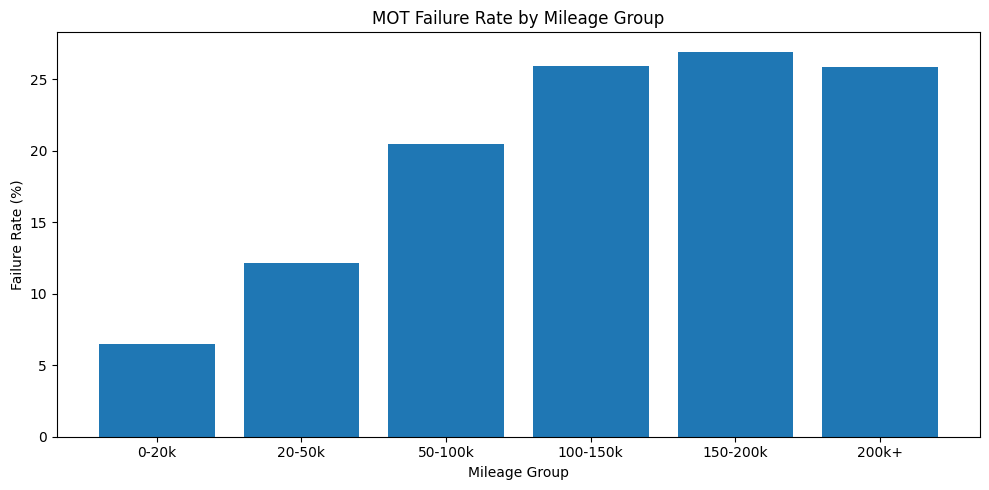

In [19]:
# Import Matplotlib for plotting
import matplotlib.pyplot as plt

# Set the correct mileage group order
mileage_order = ["0-20k", "20-50k", "50-100k", "100-150k", "150-200k", "200k+"]

# Arrange the full-year results in order
plot_data = mileage_results.reindex(mileage_order)

# Create the mileage failure rate bar chart
plt.figure(figsize=(10, 5))
plt.bar(plot_data.index, plot_data["failure_rate_%"])

# Add chart title and axis labels
plt.title("MOT Failure Rate by Mileage Group")
plt.xlabel("Mileage Group")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.show()

# Observation
The failure rate generally increases with mileage, rising from 6.48% for vehicles in the 0–20k mileage group to a peak of 26.93% in the 150–200k group. It then slightly decreases to 25.88% for vehicles above 200k mileage.

In [12]:
import pandas as pd

# Define the cleaned full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Process the dataset in batches to avoid memory issues
chunksize = 500_000

# Initialize counters for each vehicle test class
class_counts = {}

# Read the complete dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid test outcomes: Pass, Fail, and PRS
    valid = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
    ].copy()

    # Exclude records with missing vehicle class
    valid = valid.dropna(subset=["test_class_id"])

    # Calculate total tests and failures for each class
    for vehicle_class, group in valid.groupby("test_class_id"):

        # Initialize counters for each class
        if vehicle_class not in class_counts:
            class_counts[vehicle_class] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate valid test counts
        class_counts[vehicle_class]["total_tests"] += len(group)

        # Accumulate failed test counts
        class_counts[vehicle_class]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert the results into a DataFrame
class_results = pd.DataFrame.from_dict(
    class_counts,
    orient="index"
)

# Calculate the observed failure rate for each vehicle class
class_results["failure_rate_%"] = (
    class_results["failed_tests"]
    / class_results["total_tests"]
    * 100
)

# Sort classes and display the results
class_results = class_results.sort_index()

display(class_results.round(2))

,total_tests,failed_tests,failure_rate_%
0,20,5,25.00
1,248568,35776,14.39
2,877835,57360,6.53
3,12180,1406,11.54
4,40598941,7722138,19.02
5,52994,10184,19.22
7,1379960,318756,23.10


In [13]:
import pandas as pd

# Define the path of the cleaned 2024 dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Process the dataset in batches to avoid MemoryError
chunksize = 500_000

# Initialize counters for each vehicle manufacturer
make_counts = {}

# Read the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid test outcomes: Pass, Fail, and PRS
    valid = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
    ].copy()

    # Exclude records with missing manufacturer names
    valid = valid.dropna(subset=["make"])

    # Group the records by vehicle manufacturer
    for make, group in valid.groupby("make"):

        # Initialize counters for each manufacturer
        if make not in make_counts:
            make_counts[make] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate the total number of valid tests
        make_counts[make]["total_tests"] += len(group)

        # Accumulate the number of failed tests
        make_counts[make]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert the accumulated results into a DataFrame
make_results = pd.DataFrame.from_dict(
    make_counts,
    orient="index"
)

# Calculate the observed failure rate for each manufacturer
make_results["failure_rate_%"] = (
    make_results["failed_tests"]
    / make_results["total_tests"]
    * 100
)

# Sort manufacturers by highest failure rate
make_results = make_results.sort_values(
    "failure_rate_%",
    ascending=False
)

# Display the 15 manufacturers with the highest observed failure rates
display(make_results.head(15).round(2))

,total_tests,failed_tests,failure_rate_%
HONDER,1,1,100.0
CW ROAD RIPPER,1,1,100.0
ESCALADE,1,1,100.0
PHAETON,1,1,100.0
CUSTOM HARVEY COBRA,1,1,100.0
BEACH B STARD,2,2,100.0
DIRECT BIKESDB125T-E,1,1,100.0
NEW FORSE,1,1,100.0
TIGER SUPERCAT,1,1,100.0
PINZGAUER 718 TMV,1,1,100.0


In [15]:
# Set a minimum test count for reliable manufacturer comparisons
minimum_tests = 1000

# Filter manufacturers with at least 1,000 valid tests
reliable_make_results = make_results[
    make_results["total_tests"] >= minimum_tests
].copy()

# Sort manufacturers by observed failure rate in descending order
reliable_make_results = reliable_make_results.sort_values(
    "failure_rate_%",
    ascending=False
)

# Display the 15 manufacturers with the highest failure rates
print("Top 15 manufacturers with at least 1,000 valid tests:")
display(reliable_make_results.head(15).round(2))

Top 15 manufacturers with at least 1,000 valid tests:


,total_tests,failed_tests,failure_rate_%
DAEWOO,2620,830,31.68
TALBOT,14473,4558,31.49
PROTON,2985,885,29.65
LDV,15045,4427,29.43
GREAT WALL,1484,419,28.23
CHEVROLET,77123,21723,28.17
CHRYSLER-JEEP,14990,4012,26.76
DAIHATSU,23857,6354,26.63
BEDFORD,1899,504,26.54
CHRYSLER,22467,5838,25.98


In [16]:
import pandas as pd

# Define the cleaned full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Set the number of rows to process in each batch
chunksize = 500_000

# Initialize counters for each vehicle model
model_counts = {}

# Process the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid test outcomes
    valid = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
    ].copy()

    # Remove records with missing model names
    valid = valid.dropna(subset=["model"])

    # Group records by vehicle model
    for model, group in valid.groupby("model"):

        # Initialize counters for new models
        if model not in model_counts:
            model_counts[model] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate valid test counts
        model_counts[model]["total_tests"] += len(group)

        # Accumulate failed test counts
        model_counts[model]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert accumulated counts into a DataFrame
model_results = pd.DataFrame.from_dict(
    model_counts,
    orient="index"
)

# Calculate the observed failure rate for each model
model_results["failure_rate_%"] = (
    model_results["failed_tests"]
    / model_results["total_tests"]
    * 100
)

# Keep models with at least 1,000 valid tests
reliable_model_results = model_results[
    model_results["total_tests"] >= 1000
].copy()

# Sort models by observed failure rate, highest first
reliable_model_results = reliable_model_results.sort_values(
    "failure_rate_%",
    ascending=False
)

# Display the 15 models with the highest observed failure rates
print("Top 15 vehicle models with at least 1,000 valid tests:")
display(reliable_model_results.head(15).round(2))

Top 15 vehicle models with at least 1,000 valid tests:


,total_tests,failed_tests,failure_rate_%
SPACE STAR,1950,696,35.69
C15,2320,799,34.44
MPV,1137,391,34.39
CALIBER,1140,392,34.39
CABSTAR,13623,4611,33.85
FREDA,1267,426,33.62
MULTIPLA,1059,356,33.62
C8,1305,437,33.49
807,1361,453,33.28
KALOS,3967,1307,32.95


In [17]:
import pandas as pd

# Define the path to the cleaned full-year 2024 dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Set the number of rows to process in each batch
chunksize = 500_000

# Initialize a dictionary to store model-wise test counts
model_counts = {}

# Read the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only Class 7 records with valid test outcomes
    valid = chunk[
        (chunk["test_class_id"] == 7) &
        (chunk["test_result"].isin(["P", "F", "PRS"]))
    ].copy()

    # Remove records with missing model names
    valid = valid.dropna(subset=["model"])

    # Group the current batch by vehicle model
    for model, group in valid.groupby("model"):

        # Initialize counters for each new model
        if model not in model_counts:
            model_counts[model] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Accumulate valid test counts for this model
        model_counts[model]["total_tests"] += len(group)

        # Accumulate failed test counts for this model
        model_counts[model]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert the accumulated results into a DataFrame
class7_models = pd.DataFrame.from_dict(
    model_counts,
    orient="index"
)

# Calculate each model's observed failure rate
class7_models["failure_rate_%"] = (
    class7_models["failed_tests"]
    / class7_models["total_tests"]
    * 100
)

# Keep models with at least 100 valid tests
class7_models = class7_models[
    class7_models["total_tests"] >= 100
].copy()

# Sort models by observed failure rate, highest first
class7_models = class7_models.sort_values(
    "failure_rate_%",
    ascending=False
)

# Display the 15 models with the highest observed failure rates
print("Top 15 models in Class 7 with at least 100 valid tests:")
display(class7_models.head(15).round(2))

Top 15 models in Class 7 with at least 100 valid tests:


,total_tests,failed_tests,failure_rate_%
MAXUS 3.5 CDI 95 LWB,115,40,34.78
DAILY 35S14 LWB,262,90,34.35
CABSTAR,13430,4561,33.96
DAILY 35S12 SWB,173,58,33.53
308 D,499,167,33.47
DAILY 35S12 MWB,519,173,33.33
PRIMASTAR,1198,396,33.06
MAXUS,3224,1064,33.00
DAILY 35C12 XLWB,182,60,32.97
400 CONVOY TD LWB,149,49,32.89


In [18]:
# Import pandas for reading and processing the dataset
import pandas as pd

# Define the path to the cleaned 2024 dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Display the available column names from the dataset
print(pd.read_csv(file_path, nrows=5).columns.tolist())

['test_id', 'vehicle_id', 'test_date', 'test_class_id', 'test_type', 'test_result', 'test_mileage', 'postcode_area', 'make', 'model', 'colour', 'fuel_type', 'cylinder_capacity', 'first_use_date', 'completed_date', 'vehicle_age', 'vehicle_age_group', 'mileage_group']


In [19]:
import pandas as pd

# Define the path to the cleaned full-year 2024 dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Set the number of rows to process per batch
chunksize = 500_000

# Initialize a dictionary to store age and mileage group statistics
group_counts = {}

# Process the complete dataset in batches
for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Keep only valid test outcomes and records with age and mileage groups
    valid = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
        & chunk["vehicle_age_group"].notna()
        & chunk["mileage_group"].notna()
    ]

    # Group the current batch by vehicle age and mileage
    grouped = valid.groupby(
        ["vehicle_age_group", "mileage_group"]
    )

    # Accumulate total and failed tests for each combination
    for (age_group, mileage_group), group in grouped:

        # Create counters for a new age and mileage combination
        key = (age_group, mileage_group)

        if key not in group_counts:
            group_counts[key] = {
                "total_tests": 0,
                "failed_tests": 0
            }

        # Add the valid test count for this combination
        group_counts[key]["total_tests"] += len(group)

        # Add the failed test count for this combination
        group_counts[key]["failed_tests"] += int(
            (group["test_result"] == "F").sum()
        )

# Convert accumulated statistics into a DataFrame
age_mileage_results = pd.DataFrame([
    {
        "vehicle_age_group": age_group,
        "mileage_group": mileage_group,
        "total_tests": counts["total_tests"],
        "failed_tests": counts["failed_tests"]
    }
    for (age_group, mileage_group), counts in group_counts.items()
])

# Calculate the observed failure rate for each combination
age_mileage_results["failure_rate_%"] = (
    age_mileage_results["failed_tests"]
    / age_mileage_results["total_tests"]
    * 100
)

# Sort combinations by observed failure rate, highest first
age_mileage_results = age_mileage_results.sort_values(
    "failure_rate_%",
    ascending=False
)

# Display the 20 combinations with the highest observed failure rates
display(age_mileage_results.head(20).round(2))

,vehicle_age_group,mileage_group,total_tests,failed_tests,failure_rate_%
14,15+,150-200k,1200183,349483,29.12
16,15+,200k+,374100,108199,28.92
13,15+,100-150k,3101209,892600,28.78
8,10-15,150-200k,876256,234399,26.75
7,10-15,100-150k,3502544,919108,26.24
10,10-15,200k+,255487,65265,25.55
17,15+,50-100k,3243069,824577,25.43
11,10-15,50-100k,5539595,1269914,22.92
32,8-10,150-200k,210271,47011,22.36
31,8-10,100-150k,1005627,221552,22.03


In [20]:
# Display the distinct vehicle age groups and their data types
print("Vehicle age groups:")
print(age_mileage_results["vehicle_age_group"].unique())

# Display the distinct mileage groups
print("\nMileage groups:")
print(age_mileage_results["mileage_group"].unique())

# Display the first five rows without changing the existing results
display(age_mileage_results.head())

Vehicle age groups:
['15+' '10-15' '8-10' '5-8' '0-3' '3-5']

Mileage groups:
['150-200k' '200k+' '100-150k' '50-100k' '20-50k' '0-20k']


,vehicle_age_group,mileage_group,total_tests,failed_tests,failure_rate_%
14,15+,150-200k,1200183,349483,29.119143
16,15+,200k+,374100,108199,28.922481
13,15+,100-150k,3101209,892600,28.782323
8,10-15,150-200k,876256,234399,26.750059
7,10-15,100-150k,3502544,919108,26.241155


### Interpretation

The heatmap indicates that MOT failure rates generally increase with vehicle age and mileage. Older, high-mileage vehicles show higher observed failure rates than newer, low-mileage vehicles. However, the slight decrease in the 200k+ mileage group shows that the relationship is not perfectly consistent. These results indicate an association between vehicle age, mileage, and MOT failure rates, but do not establish causation.

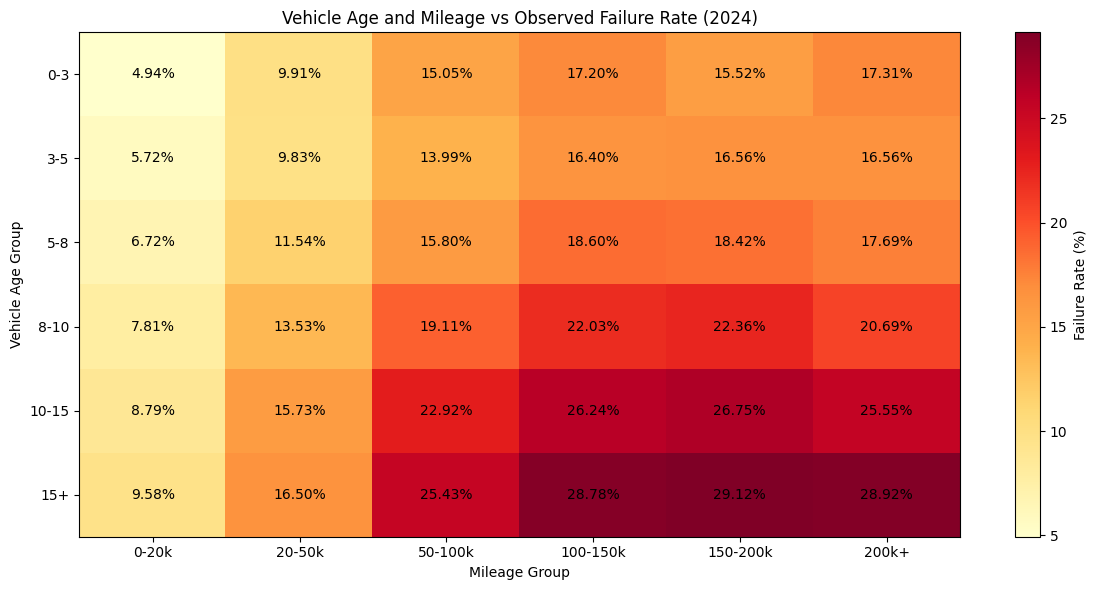

In [22]:
# Import Matplotlib and NumPy for creating the heatmap
import matplotlib.pyplot as plt
import numpy as np

# Define the correct order of vehicle age groups
age_order = ["0-3", "3-5", "5-8", "8-10", "10-15", "15+"]

# Define the correct order of mileage groups
mileage_order = [
    "0-20k", "20-50k", "50-100k",
    "100-150k", "150-200k", "200k+"
]

# Convert the failure-rate results into a matrix
heatmap_data = age_mileage_results.pivot(
    index="vehicle_age_group",
    columns="mileage_group",
    values="failure_rate_%"
)

# Arrange age and mileage groups in the correct order
heatmap_data = heatmap_data.reindex(
    index=age_order,
    columns=mileage_order
)

# Convert the matrix into a NumPy array for plotting
data = heatmap_data.to_numpy(dtype=float)

# Create the heatmap figure
fig, ax = plt.subplots(figsize=(12, 6))

# Display the heatmap using Matplotlib
image = ax.imshow(data, cmap="YlOrRd", aspect="auto")

# Add mileage-group labels to the x-axis
ax.set_xticks(np.arange(len(mileage_order)))
ax.set_xticklabels(mileage_order)

# Add vehicle-age labels to the y-axis
ax.set_yticks(np.arange(len(age_order)))
ax.set_yticklabels(age_order)

# Display the failure rate inside each cell
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if not np.isnan(data[i, j]):
            ax.text(
                j, i, f"{data[i, j]:.2f}%",
                ha="center", va="center"
            )

# Add chart title and axis labels
ax.set_title("Vehicle Age and Mileage vs Observed Failure Rate (2024)")
ax.set_xlabel("Mileage Group")
ax.set_ylabel("Vehicle Age Group")

# Add a colour bar to represent failure rates
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Failure Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

### Observation – Vehicle Age and Mileage Analysis

- Vehicles aged **15+ years** with mileage between **150,000 and 200,000** recorded the highest observed failure rate of **29.12%**.
- Vehicles aged **0–3 years** with mileage below **20,000** recorded the lowest observed failure rate of **4.94%**.
- Failure rates generally increased with vehicle age across mileage groups.
- Failure rates generally increased with mileage, although a slight decrease was observed in some higher-mileage groups.
- Overall, the results indicate an association between **vehicle age, mileage, and MOT failure rates**.

## Missing Value Analysis

This analysis identifies missing values across the complete 2024 MOT dataset. It measures the number of missing values in each column and counts the rows containing at least one missing value. This helps assess data completeness before further analysis.

In [23]:
# Import Pandas for data processing
import pandas as pd

# Define the dataset file path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Initialize a dictionary to store missing-value counts
missing_counts = {}

# Initialize counters for total rows and rows with missing values
total_rows = 0
rows_with_missing = 0

# Read the full dataset in chunks to avoid memory errors
for chunk in pd.read_csv(file_path, chunksize=500_000):

    # Count missing values in each column
    chunk_missing = chunk.isnull().sum()

    # Add the current chunk's missing counts to the overall counts
    for column, count in chunk_missing.items():
        missing_counts[column] = missing_counts.get(column, 0) + int(count)

    # Count the total number of rows processed
    total_rows += len(chunk)

    # Count rows containing at least one missing value
    rows_with_missing += int(chunk.isnull().any(axis=1).sum())

# Convert missing-value counts into a Pandas Series
missing_summary = pd.Series(missing_counts)

# Display only columns containing missing values, sorted by count
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

# Display the full-year missing-value analysis
print("Total Rows Analyzed:", total_rows)
print("\nMissing Values by Column:")
print(missing_summary)
print("\nTotal Missing Values:", int(missing_summary.sum()))
print("Rows with at Least One Missing Value:", rows_with_missing)

Total Rows Analyzed: 43441151

Missing Values by Column:
cylinder_capacity    519008
test_mileage         351981
mileage_group        351981
vehicle_age_group       491
vehicle_age              57
first_use_date           57
model                    27
make                      1
dtype: int64

Total Missing Values: 1223603
Rows with at Least One Missing Value: 868320


## Test Results by Mileage Availability

This analysis compares MOT test outcomes between records with missing mileage and records with available mileage across the complete 2024 dataset. It helps assess whether missing mileage is associated with differences in the distribution of test outcomes.

In [24]:
# Initialize dictionaries to count test outcomes by mileage availability
missing_mileage_results = {}
available_mileage_results = {}

# Process the complete dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=500_000):

    # Count test outcomes for records with missing mileage
    missing_counts = chunk.loc[
        chunk["test_mileage"].isna(), "test_result"
    ].value_counts()

    # Count test outcomes for records with available mileage
    available_counts = chunk.loc[
        chunk["test_mileage"].notna(), "test_result"
    ].value_counts()

    # Accumulate missing-mileage outcome counts
    for result, count in missing_counts.items():
        missing_mileage_results[result] = (
            missing_mileage_results.get(result, 0) + int(count)
        )

    # Accumulate available-mileage outcome counts
    for result, count in available_counts.items():
        available_mileage_results[result] = (
            available_mileage_results.get(result, 0) + int(count)
        )

# Display test outcomes for records with missing mileage
print("Test Results WITH Missing Mileage:")
print(pd.Series(missing_mileage_results).sort_values(ascending=False))

# Display test outcomes for records with available mileage
print("\nTest Results WITH Available Mileage:")
print(pd.Series(available_mileage_results).sort_values(ascending=False))

Test Results WITH Missing Mileage:
ABR      213858
P         72787
F         34229
ABA       24686
PRS        6407
ABRVE        14
dtype: int64

Test Results WITH Available Mileage:
P        32968285
F         8111396
PRS       1977394
ABR         27567
ABA          4521
ABRVE           7
dtype: int64


In [25]:
# Initialize counters for missing values in the full dataset
missing_mileage = 0
missing_cylinder_capacity = 0
missing_mileage_group = 0

# Process the full dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=500_000):

    # Count missing mileage values
    missing_mileage += int(chunk["test_mileage"].isnull().sum())

    # Count missing cylinder capacity values
    missing_cylinder_capacity += int(chunk["cylinder_capacity"].isnull().sum())

    # Count missing mileage-group values
    missing_mileage_group += int(chunk["mileage_group"].isnull().sum())

# Display full-dataset missing-value counts
print("Missing mileage count:", missing_mileage)
print("Missing cylinder capacity:", missing_cylinder_capacity)
print("Missing mileage group:", missing_mileage_group)

Missing mileage count: 351981
Missing cylinder capacity: 519008
Missing mileage group: 351981


## Vehicle Age Calculation Validation

This analysis validates the calculated vehicle age by comparing it with the age derived from the first-use date and MOT test date across the complete 2024 dataset.

In [27]:
# Initialize counters for full-dataset vehicle age validation
records_checked = 0
records_over_one_day_difference = 0
maximum_age_difference = 0.0
sample_records = []

# Process the complete dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=500_000):

    # Convert date columns to datetime format
    first_use_date = pd.to_datetime(chunk["first_use_date"], errors="coerce")
    test_date = pd.to_datetime(chunk["test_date"], errors="coerce")

    # Calculate vehicle age in years from the two dates
    calculated_age = (test_date - first_use_date).dt.days / 365.25

    # Compare calculated age with the existing vehicle_age column
    age_difference = (chunk["vehicle_age"] - calculated_age).abs()

    # Select records where both age values are available
    valid = age_difference.notna()

    # Count records included in the validation
    records_checked += int(valid.sum())

    # Count records with an age difference greater than one day
    records_over_one_day_difference += int(
        (age_difference[valid] > (1 / 365.25)).sum()
    )

    # Track the maximum observed age difference
    if valid.any():
        chunk_max_difference = float(age_difference[valid].max())
        maximum_age_difference = max(
            maximum_age_difference, chunk_max_difference
        )

    # Save a small sample of records for inspection
    if len(sample_records) < 10:
        sample = chunk.loc[
            valid,
            ["first_use_date", "test_date", "vehicle_age"]
        ].copy()

        # Add the calculated age and absolute difference
        sample["calculated_vehicle_age"] = calculated_age[valid]
        sample["vehicle_age_difference"] = age_difference[valid]

        # Store only enough records to reach the sample limit
        remaining = 10 - len(sample_records)
        sample_records.extend(sample.head(remaining).to_dict("records"))

# Display full-dataset validation results
print("Vehicle Age Validation")
print("----------------------")
print("Records checked:", records_checked)
print("Records with age difference > 1 day:", records_over_one_day_difference)
print("Maximum age difference (years):", maximum_age_difference)

# Display sample records for inspection
print("\nSample records:")
print(pd.DataFrame(sample_records).to_string(index=False))

Vehicle Age Validation
----------------------
Records checked: 43441094
Records with age difference > 1 day: 0
Maximum age difference (years): 1.4210854715202004e-14

Sample records:
first_use_date  test_date  vehicle_age  calculated_vehicle_age  vehicle_age_difference
    2010-09-01 2024-01-02    13.336071               13.336071            1.776357e-15
    1998-01-06 2024-01-23    26.045175               26.045175            0.000000e+00
    1998-12-31 2024-01-23    25.062286               25.062286            0.000000e+00
    2010-03-10 2024-01-17    13.856263               13.856263            1.776357e-15
    2008-01-26 2024-01-26    16.000000               16.000000            0.000000e+00
    2008-12-17 2024-01-09    15.060917               15.060917            0.000000e+00
    2008-12-17 2024-01-09    15.060917               15.060917            0.000000e+00
    2002-09-11 2024-01-26    21.374401               21.374401            3.552714e-15
    2002-09-11 2024-01-26    21.37

## Duplicate Records Analysis
This analysis checks the complete 2024 MOT dataset for exact duplicate rows and repeated test IDs. It helps identify duplicate records before further analysis.

In [29]:
# Initialize the counter for exact duplicates found within chunks
duplicate_rows_within_chunks = 0

# Track the total number of records processed
total_records_checked = 0

# Read the complete dataset in chunks to reduce memory usage
for chunk in pd.read_csv(file_path, chunksize=500_000):

    # Count exact duplicate rows within the current chunk
    duplicate_rows_within_chunks += int(chunk.duplicated().sum())

    # Update the total number of records processed
    total_records_checked += len(chunk)

# Display the results
print("Total records checked:", total_records_checked)
print("Exact duplicates found within chunks:", duplicate_rows_within_chunks)

Total records checked: 43441151
Exact duplicates found within chunks: 0


## Repeated Test ID Analysis

This analysis checks whether test IDs appear more than once in the complete 2024 MOT dataset. It processes the dataset in chunks to reduce memory usage.

In [31]:
# Import Pandas to analyse repeated test IDs.
import pandas as pd

# Read the extracted test IDs from the existing file.
test_ids = pd.read_csv(
    "sorted_test_ids.txt",
    header=None,
    names=["test_id"],
    dtype={"test_id": "string"}
)

# Count occurrences of each test ID.
test_id_counts = test_ids["test_id"].value_counts()

# Filter IDs that appear more than once.
repeated_ids = test_id_counts[test_id_counts > 1]

# Display the duplicate analysis results.
print("Total test IDs:", len(test_ids))
print("Repeated test IDs:", len(repeated_ids))
print("Records belonging to repeated IDs:", repeated_ids.sum())

Total test IDs: 43441151
Repeated test IDs: 829687
Records belonging to repeated IDs: 1672214


### Observation
The analysis identified 829,687 test IDs occurring more than once, involving 1,672,214 records. These repeated IDs require further investigation to determine whether they represent duplicate records or multiple tests associated with the same ID.

## Repeated Test ID Verification

This analysis investigates whether repeated test IDs belong to the same vehicle and test date or represent different test records.

In [37]:
# Select columns needed to investigate repeated test IDs.
columns_to_check = [
    "test_id", "vehicle_id", "test_date", "test_result", "test_mileage"
]

# Store matching records from each dataset chunk.
repeated_records = []

# Read the full dataset in chunks to manage memory usage.
for chunk in pd.read_csv(
    file_path,
    usecols=columns_to_check,
    chunksize=500_000
):
    # Keep records whose test IDs were identified as repeated.
    matching_records = chunk[
        chunk["test_id"].astype("string").isin(repeated_ids.index)
    ]

    # Retain matching records for verification.
    if not matching_records.empty:
        repeated_records.append(matching_records)

# Combine matching records from all chunks.
repeated_df = pd.concat(repeated_records, ignore_index=True)

# Summarise the records associated with each repeated test ID.
repeated_id_summary = repeated_df.groupby("test_id").agg(
    record_count=("test_id", "size"),
    unique_vehicles=("vehicle_id", "nunique"),
    unique_test_dates=("test_date", "nunique"),
    unique_results=("test_result", "nunique"),
    unique_mileages=("test_mileage", "nunique")
).reset_index()

# Count repeated IDs associated with multiple vehicles or test dates.
multiple_vehicles = (
    repeated_id_summary["unique_vehicles"] > 1
).sum()

multiple_dates = (
    repeated_id_summary["unique_test_dates"] > 1
).sum()

# Display verification totals.
print("Repeated IDs analysed:", len(repeated_id_summary))
print("Records analysed:", len(repeated_df))
print("Repeated IDs linked to multiple vehicles:", multiple_vehicles)
print("Repeated IDs linked to multiple test dates:", multiple_dates)

# Display a sample for manual verification.
print("\nSample repeated ID records:")
print(repeated_id_summary.head(10))

Repeated IDs analysed: 829687
Records analysed: 1672214
Repeated IDs linked to multiple vehicles: 8427
Repeated IDs linked to multiple test dates: 0

Sample repeated ID records:
   test_id  record_count  unique_vehicles  unique_test_dates  unique_results  \
0     1137             2                1                  1               1   
1     6067             2                1                  1               1   
2     8509             2                1                  1               1   
3     8845             2                1                  1               1   
4    10929             2                1                  1               1   
5    11131             2                1                  1               1   
6    13103             2                1                  1               1   
7    15747             2                1                  1               1   
8    23365             2                1                  1               1   
9    25001            

In [30]:
# Count how many times each test ID appears in the full dataset.
repeated_id_counts = {}

# Read test IDs in chunks to avoid loading the full dataset into memory.
for chunk in pd.read_csv(
    file_path,
    usecols=["test_id"],
    dtype={"test_id": "string"},
    chunksize=500_000
):
    # Count test IDs within the current chunk.
    counts = chunk["test_id"].value_counts()

    # Accumulate counts across chunks.
    for test_id, count in counts.items():
        repeated_id_counts[test_id] = (
            repeated_id_counts.get(test_id, 0) + count
        )

# Keep IDs that appear more than once in the full dataset.
repeated_ids = pd.Series(repeated_id_counts)
repeated_ids = repeated_ids[repeated_ids > 1]

# Display the number of repeated test IDs.
print("Repeated test IDs:", f"{len(repeated_ids):,}")

Repeated test IDs: 829,687


In [31]:
# Define the columns needed to investigate repeated test IDs.
columns_to_check = [
    "test_id",
    "vehicle_id",
    "test_date",
    "test_result",
    "test_mileage"
]

# Store matching records from each dataset chunk.
repeated_records = []

# Read the required columns in chunks to manage memory usage.
for chunk in pd.read_csv(
    file_path,
    usecols=columns_to_check,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    # Select records whose test IDs occur more than once in the full dataset.
    matching_records = chunk[
        chunk["test_id"].isin(repeated_ids.index)
    ]

    # Save matching records for the repeated-ID investigation.
    if not matching_records.empty:
        repeated_records.append(matching_records)

# Combine matching records into one DataFrame.
repeated_df = pd.concat(repeated_records, ignore_index=True)

# Display the resulting shape.
print("Repeated-ID records:", f"{len(repeated_df):,}")
print("Columns analysed:", len(repeated_df.columns))

Repeated-ID records: 1,672,214
Columns analysed: 5


In [32]:
# Check whether repeated test IDs are associated with multiple vehicles.
vehicles_per_id = repeated_df.groupby("test_id")["vehicle_id"].nunique()

# Count repeated test IDs associated with multiple vehicles.
multiple_vehicles = (vehicles_per_id > 1).sum()

# Check whether repeated test IDs have multiple test dates.
dates_per_id = repeated_df.groupby("test_id")["test_date"].nunique()

# Count repeated test IDs associated with multiple dates.
multiple_dates = (dates_per_id > 1).sum()

# Check whether repeated test IDs have multiple test results.
results_per_id = repeated_df.groupby("test_id")["test_result"].nunique()

# Count repeated test IDs with different test results.
multiple_results = (results_per_id > 1).sum()

# Check whether repeated test IDs have multiple mileage values.
mileage_per_id = repeated_df.groupby("test_id")["test_mileage"].nunique()

# Count repeated test IDs with different mileage values.
multiple_mileage = (mileage_per_id > 1).sum()

# Display the investigation results.
print("Repeated test IDs linked to multiple vehicles:", f"{multiple_vehicles:,}")
print("Repeated test IDs linked to multiple dates:", f"{multiple_dates:,}")
print("Repeated test IDs with different results:", f"{multiple_results:,}")
print("Repeated test IDs with different mileage:", f"{multiple_mileage:,}")

Repeated test IDs linked to multiple vehicles: 8,427
Repeated test IDs linked to multiple dates: 0
Repeated test IDs with different results: 1
Repeated test IDs with different mileage: 22,294


In [33]:
# Count exact duplicate records across the five columns being investigated.
duplicate_count = repeated_df.duplicated().sum()

# Calculate the percentage of repeated-ID records that are duplicates.
duplicate_percentage = (duplicate_count / len(repeated_df)) * 100

# Display the duplicate investigation results.
print("Duplicate records across five columns:", f"{duplicate_count:,}")
print("Percentage of repeated-ID records:", f"{duplicate_percentage:.2f}%")

Duplicate records across five columns: 810,668
Percentage of repeated-ID records: 48.48%


In [34]:
# Display a small sample of records duplicated across the five selected columns.
duplicate_sample = repeated_df[
    repeated_df.duplicated(keep=False)
].head(10)

# Show the sample without row numbers.
print(duplicate_sample.to_string(index=False))

   test_id  vehicle_id  test_date test_result  test_mileage
 300046445   844431602 2024-01-23           P      133969.0
 300046445   844431602 2024-01-23           P      133969.0
 326013157  1286663300 2024-01-26           F      142959.0
 326013157  1286663300 2024-01-26           F      142959.0
1295031079   545711664 2024-01-16           P      184274.0
1295031079   545711664 2024-01-16           P      184274.0
 720206643   433764988 2024-01-08           P      113807.0
 720206643   433764988 2024-01-08           P      113807.0
1988622513   895760856 2024-01-23           P      131937.0
1988622513   895760856 2024-01-23           P      131937.0


### Repeated Test ID and Duplicate Record Analysis

- Total repeated test IDs: 829,687
- Records associated with repeated test IDs: 1,672,214
- Repeated test IDs linked to multiple vehicles: 8,427
- Repeated test IDs linked to multiple dates: 0
- Repeated test IDs with different test results: 1
- Repeated test IDs with different mileage values: 22,294
- Duplicate records across five selected columns: 810,668 (48.48%)

Observation:
Several records share the same test ID and identical values across the five selected columns. Some repeated test IDs are associated with multiple vehicles or different mileage values. These findings require further investigation before classifying records as data errors. Full-row duplicates across all 18 columns have not been verified.

---------------

## Duplicate Record Verification

This analysis checks whether records sharing the same test ID have identical vehicle IDs, test results, and mileage values.

In [33]:
# Compare record values within each repeated test ID.
duplicate_check = repeated_df.groupby("test_id").agg(
    record_count=("test_id", "size"),
    unique_vehicles=("vehicle_id", "nunique"),
    unique_results=("test_result", "nunique"),
    unique_mileages=("test_mileage", "nunique")
).reset_index()

# Identify IDs whose records agree on all three fields.
same_values = duplicate_check[
    (duplicate_check["unique_vehicles"] == 1) &
    (duplicate_check["unique_results"] == 1) &
    (duplicate_check["unique_mileages"] == 1)
]

# Identify IDs with at least one differing field.
different_values = duplicate_check[
    (duplicate_check["unique_vehicles"] > 1) |
    (duplicate_check["unique_results"] > 1) |
    (duplicate_check["unique_mileages"] > 1)
]

# Display the verification counts.
print("Repeated IDs with matching vehicle, result and mileage:", len(same_values))
print("Repeated IDs with differing values:", len(different_values))

Repeated IDs with matching vehicle, result and mileage: 778726
Repeated IDs with differing values: 30689


### Observation
Among repeated test IDs, 778,726 IDs have matching vehicle IDs, test results, and mileage values. Another 30,689 IDs have differences in at least one of these fields. Matching values alone do not confirm exact duplicate records.

In [35]:
# Define the columns required for duplicate-record verification.
columns_to_check = [
    "test_id",
    "vehicle_id",
    "test_date",
    "test_result",
    "test_mileage"
]

# Store records linked to repeated test IDs.
repeated_records = []

# Read the dataset in chunks to avoid loading the full dataset into memory.
for chunk in pd.read_csv(
    file_path,
    usecols=columns_to_check,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    # Select records whose test IDs appear more than once.
    matching_records = chunk[
        chunk["test_id"].isin(repeated_ids.index)
    ]

    # Store matching records for further verification.
    if not matching_records.empty:
        repeated_records.append(matching_records)

# Combine the selected records into one DataFrame.
repeated_df = pd.concat(repeated_records, ignore_index=True)

# Display the number of records loaded for verification.
print("Repeated-ID records:", f"{len(repeated_df):,}")

Repeated-ID records: 1,672,214


In [36]:
# Check duplicate rows using only the five selected verification columns.
# This does not verify exact duplicates across all 18 dataset columns.
duplicate_rows_in_selected_columns = repeated_df.duplicated(
    keep="first"
).sum()

# Display the result with an accurate description.
print(
    "Duplicate rows across the five selected columns:",
    f"{duplicate_rows_in_selected_columns:,}"
)

Duplicate rows across the five selected columns: 810,668


In [2]:
# Import Pandas and define the dataset path.
import pandas as pd

# Set the path to the cleaned 2024 MOT dataset.
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv"

# Verify that the dataset path is accessible.
print("Dataset path:", file_path)
print("File exists:", __import__("os").path.exists(file_path))

Dataset path: D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_2024_final.csv
File exists: True


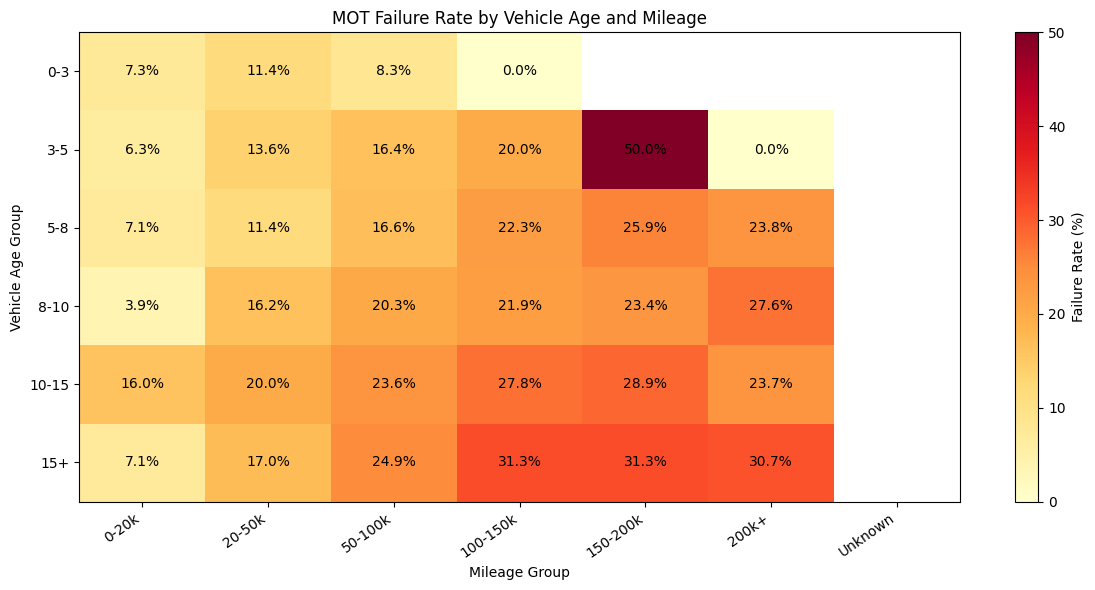

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare failure rate data
heatmap_data = combined_summary.pivot(
    index="vehicle_age_group",
    columns="mileage_group",
    values="failure_rate"
)

# Arrange categories in the correct order
age_order = ["0-3", "3-5", "5-8", "8-10", "10-15", "15+"]

mileage_order = [
    "0-20k",
    "20-50k",
    "50-100k",
    "100-150k",
    "150-200k",
    "200k+",
    "Unknown"
]

heatmap_data = heatmap_data.reindex(
    index=age_order,
    columns=mileage_order
)

# Create heatmap using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))

values = heatmap_data.to_numpy(dtype=float)
masked_values = np.ma.masked_invalid(values)

im = ax.imshow(
    masked_values,
    aspect="auto",
    interpolation="nearest",
    cmap="YlOrRd"
)

# Add axis labels
ax.set_xticks(range(len(mileage_order)))
ax.set_xticklabels(mileage_order, rotation=35, ha="right")

ax.set_yticks(range(len(age_order)))
ax.set_yticklabels(age_order)

ax.set_xlabel("Mileage Group")
ax.set_ylabel("Vehicle Age Group")
ax.set_title("MOT Failure Rate by Vehicle Age and Mileage")

# Display percentages inside cells
for i in range(len(age_order)):
    for j in range(len(mileage_order)):
        value = values[i, j]

        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center",
                va="center"
            )

# Add colour bar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Failure Rate (%)")

plt.tight_layout()
plt.show()

In [36]:
# Identify high-failure-rate age and mileage combinations

risk_summary = combined_summary.sort_values(
    by="failure_rate",
    ascending=False
)

print(
    risk_summary[
        [
            "vehicle_age_group",
            "mileage_group",
            "total_tests",
            "failed_tests",
            "failure_rate"
        ]
    ].head(15).to_string(index=False)
)

vehicle_age_group mileage_group  total_tests  failed_tests  failure_rate
              3-5      150-200k            4             2         50.00
              15+      100-150k          865           271         31.33
              15+      150-200k          326           102         31.29
              15+         200k+           75            23         30.67
            10-15      150-200k          246            71         28.86
            10-15      100-150k          920           256         27.83
             8-10         200k+           29             8         27.59
              5-8      150-200k           54            14         25.93
              15+       50-100k          699           174         24.89
              5-8         200k+           42            10         23.81
            10-15         200k+           59            14         23.73
            10-15       50-100k         1138           269         23.64
             8-10      150-200k           77       

In [52]:
import pandas as pd

min_date = None
max_date = None
total_records = 0

for chunk in pd.read_csv(
    file_path,
    usecols=["test_date"],
    chunksize=500_000,
    dtype={"test_date": "string"}
):
    dates = pd.to_datetime(
        chunk["test_date"],
        errors="coerce"
    )

    chunk_min = dates.min()
    chunk_max = dates.max()

    if pd.notna(chunk_min):
        min_date = chunk_min if min_date is None else min(min_date, chunk_min)

    if pd.notna(chunk_max):
        max_date = chunk_max if max_date is None else max(max_date, chunk_max)

    total_records += len(chunk)

print("Total records:", total_records)
print("Minimum test date:", min_date)
print("Maximum test date:", max_date)

Total records: 43441151
Minimum test date: 2024-01-01 00:00:00
Maximum test date: 2024-12-30 00:00:00


In [53]:
monthly_counts = {}

for chunk in pd.read_csv(
    file_path,
    usecols=["test_date", "test_result"],
    chunksize=500_000
):
    chunk["test_date"] = pd.to_datetime(
        chunk["test_date"], errors="coerce"
    )

    chunk = chunk[
        chunk["test_result"].isin(["P", "F", "PRS"])
    ].copy()

    chunk["month"] = chunk["test_date"].dt.to_period("M")

    summary = chunk.groupby("month").agg(
        total_tests=("test_result", "count"),
        failed_tests=("test_result", lambda x: (x == "F").sum())
    )

    for month, row in summary.iterrows():
        if month not in monthly_counts:
            monthly_counts[month] = [0, 0]

        monthly_counts[month][0] += int(row["total_tests"])
        monthly_counts[month][1] += int(row["failed_tests"])

monthly_summary = pd.DataFrame(
    [
        {
            "month": str(month),
            "total_tests": counts[0],
            "failed_tests": counts[1],
            "failure_rate": round(
                counts[1] / counts[0] * 100, 2
            ) if counts[0] else 0
        }
        for month, counts in sorted(monthly_counts.items())
    ]
)

print(monthly_summary.to_string(index=False))

  month  total_tests  failed_tests  failure_rate
2024-01      3824732        769918         20.13
2024-02      3644406        698971         19.18
2024-03      4104319        743616         18.12
2024-04      3178070        603620         18.99
2024-05      3175398        578285         18.21
2024-06      3328593        605087         18.18
2024-07      3660772        690681         18.87
2024-08      3558362        660898         18.57
2024-09      4041340        737638         18.25
2024-10      4264541        833798         19.55
2024-11      3712063        724604         19.52
2024-12      2677902        498509         18.62


## Monthly MOT Failure Rate Trend

This line chart shows how the MOT failure rate changes month by month across the 2024 dataset.

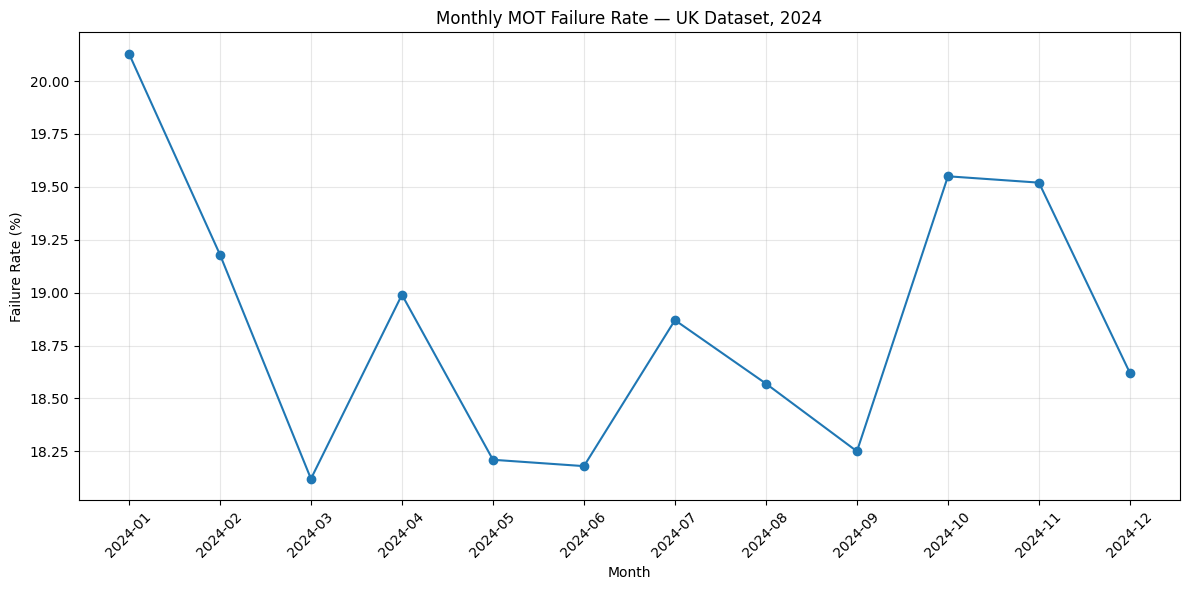

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary["month"],
    monthly_summary["failure_rate"],
    marker="o"
)

plt.title("Monthly MOT Failure Rate — UK Dataset, 2024")
plt.xlabel("Month")
plt.ylabel("Failure Rate (%)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observation
The monthly MOT failure rate fluctuated throughout 2024. January recorded the highest failure rate at 20.13%, while March recorded the lowest at 18.12%. The failure rate increased again during October and November before decreasing in December.

## Overall MOT Failure Rate

This analysis calculates the overall failure rate across all valid MOT test outcomes (Pass, Fail, and Pass after Rectification) in the complete 2024 dataset.

In [55]:
total_tests_2024 = monthly_summary["total_tests"].sum()
total_failures_2024 = monthly_summary["failed_tests"].sum()

overall_failure_rate = (
    total_failures_2024 / total_tests_2024
) * 100

print("Total valid MOT tests:", f"{total_tests_2024:,}")
print("Total failed tests:", f"{total_failures_2024:,}")
print("Overall failure rate:", f"{overall_failure_rate:.2f}%")

Total valid MOT tests: 43,170,498
Total failed tests: 8,145,625
Overall failure rate: 18.87%


In [24]:
import os
import matplotlib.pyplot as plt
from IPython.display import display, Image

visualization_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\Visualizations"

print("Available Full-Year EDA Graphs:")

for file in sorted(os.listdir(visualization_path)):
    if file.endswith(".png"):
        print(file)

Available Full-Year EDA Graphs:
age_failure_rate.png
category_analysis.png
colour_failure_rate.png
correlation_analysis.png
cylinder_capacity_failure_rate.png
distribution_analysis.png
fuel_failure_rate.png
make_failure_rate.png
model_failure_rate.png
monthly_failure_trend.png
postcode_failure_rate.png
test_class_failure_rate.png
test_type_failure_rate.png
trend_analysis.png


distribution_analysis.png


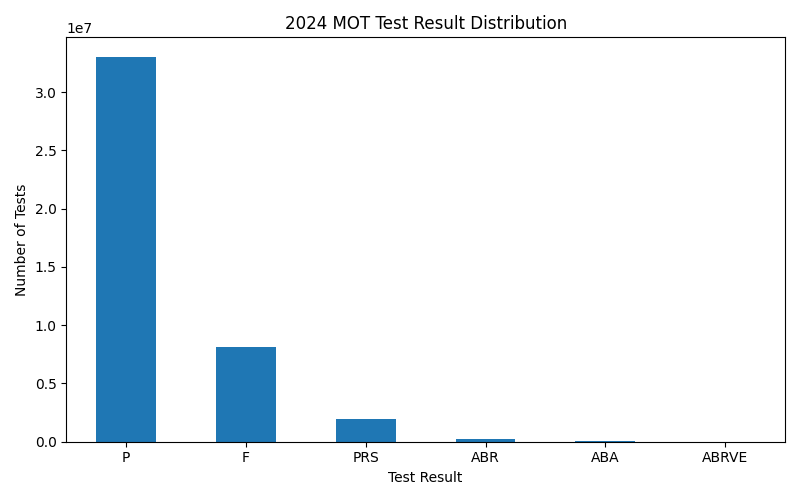

trend_analysis.png


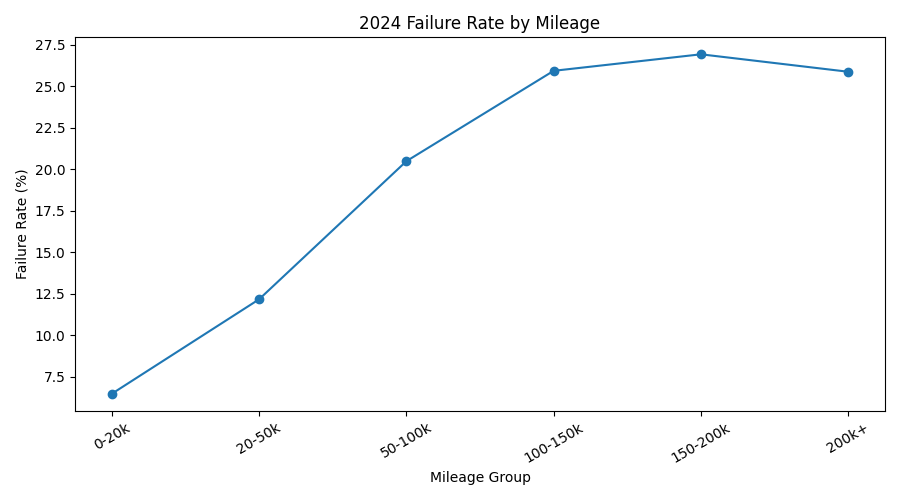

age_failure_rate.png


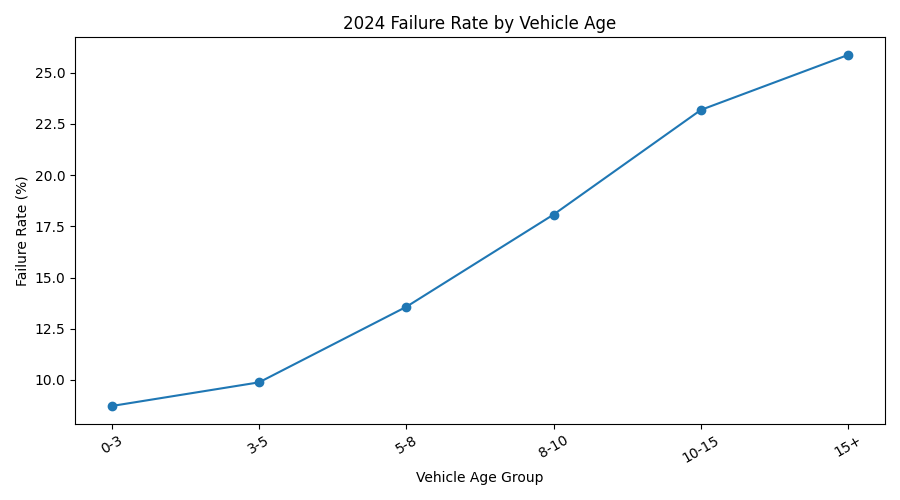

make_failure_rate.png


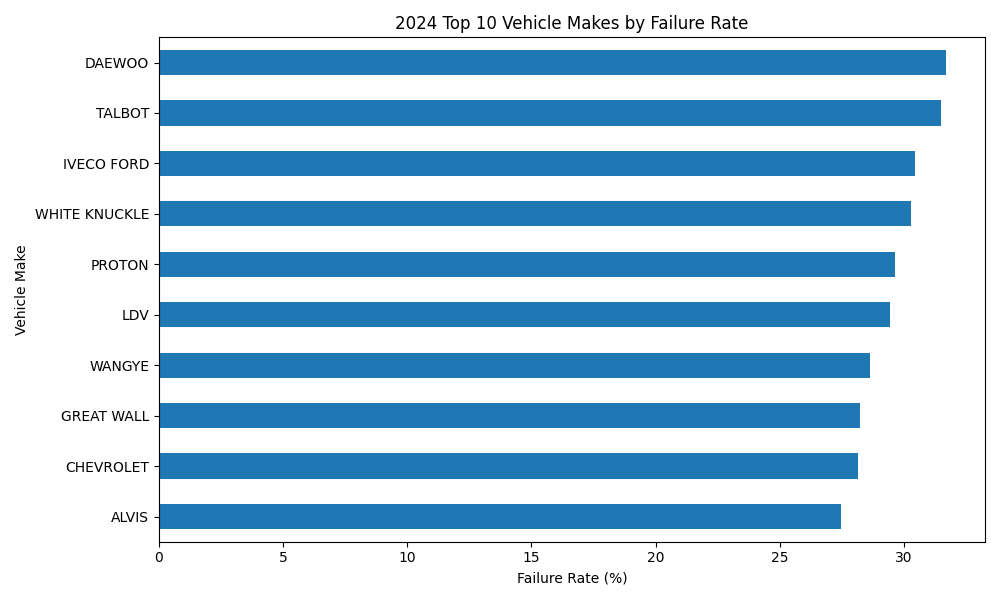

fuel_failure_rate.png


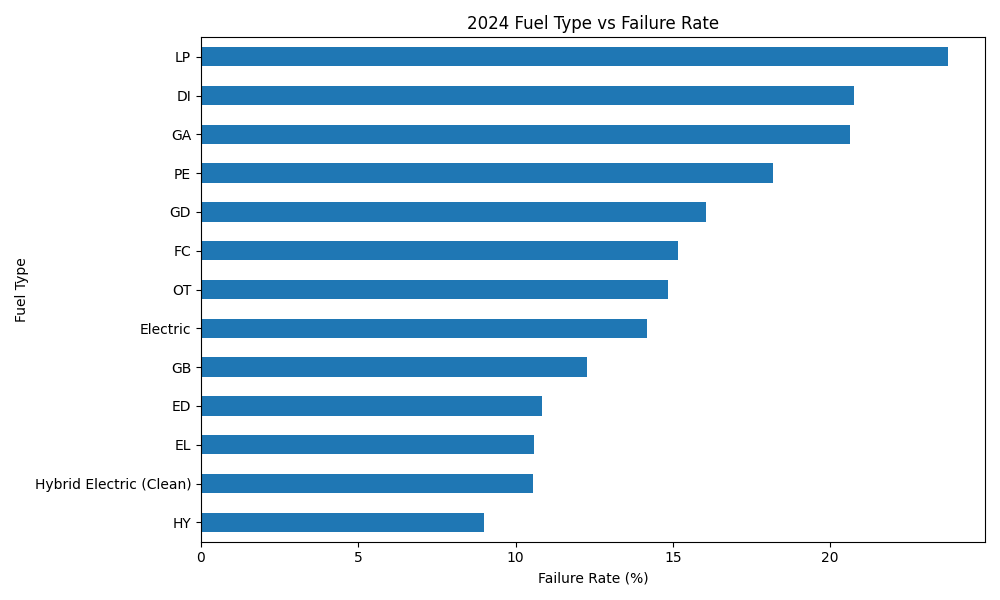

test_class_failure_rate.png


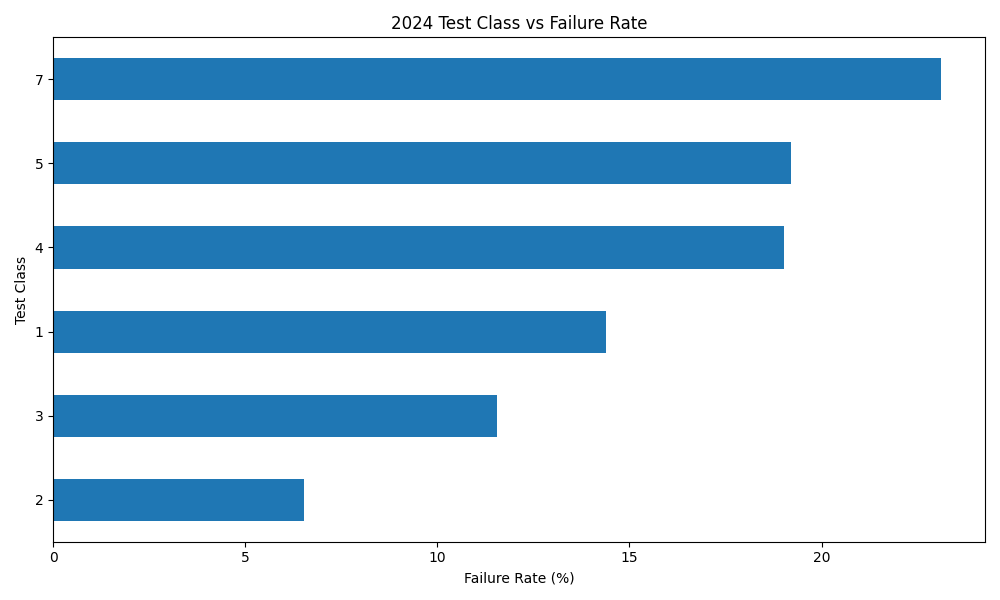

model_failure_rate.png


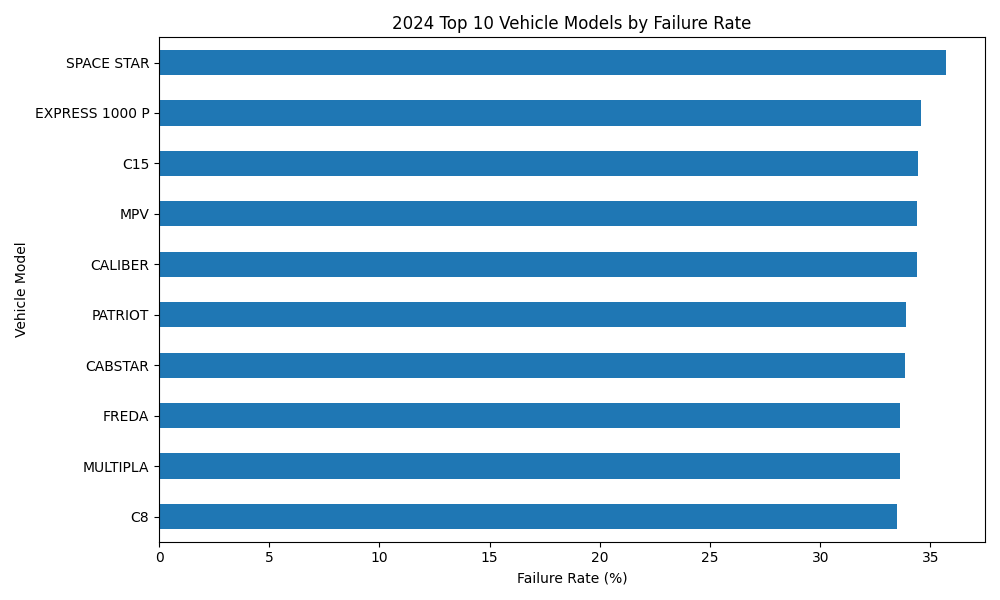

postcode_failure_rate.png


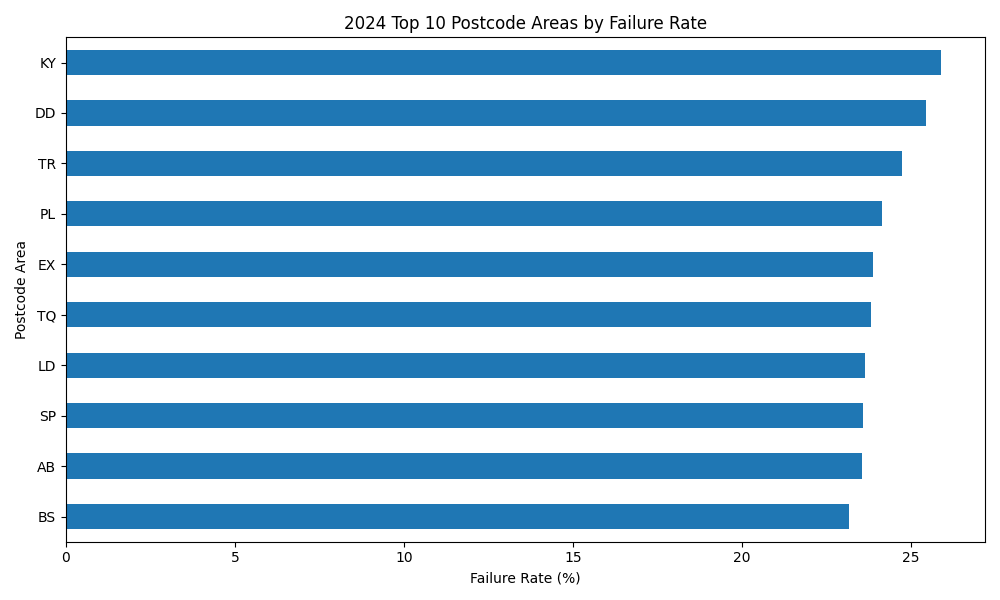

monthly_failure_trend.png


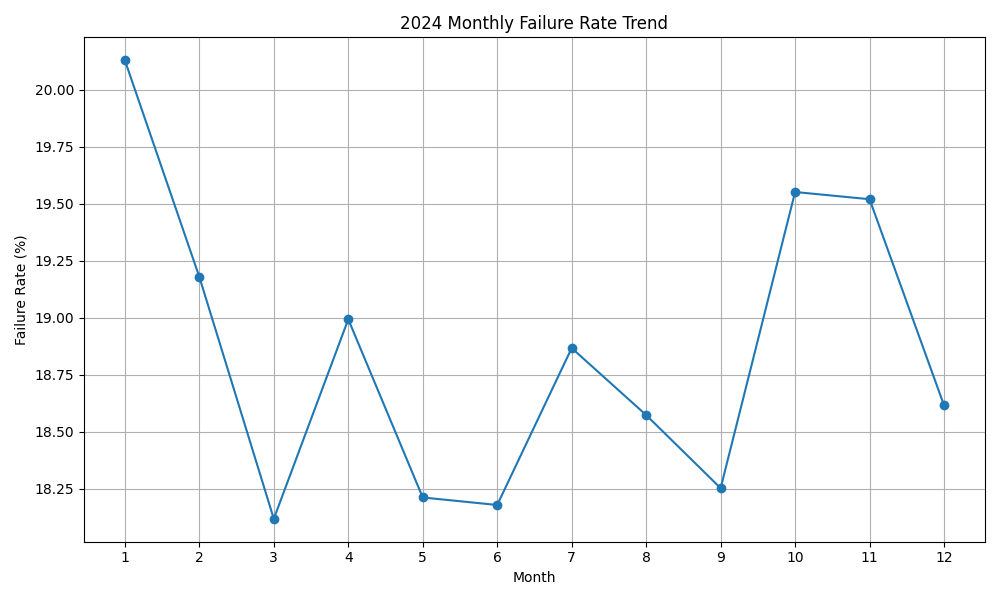

colour_failure_rate.png


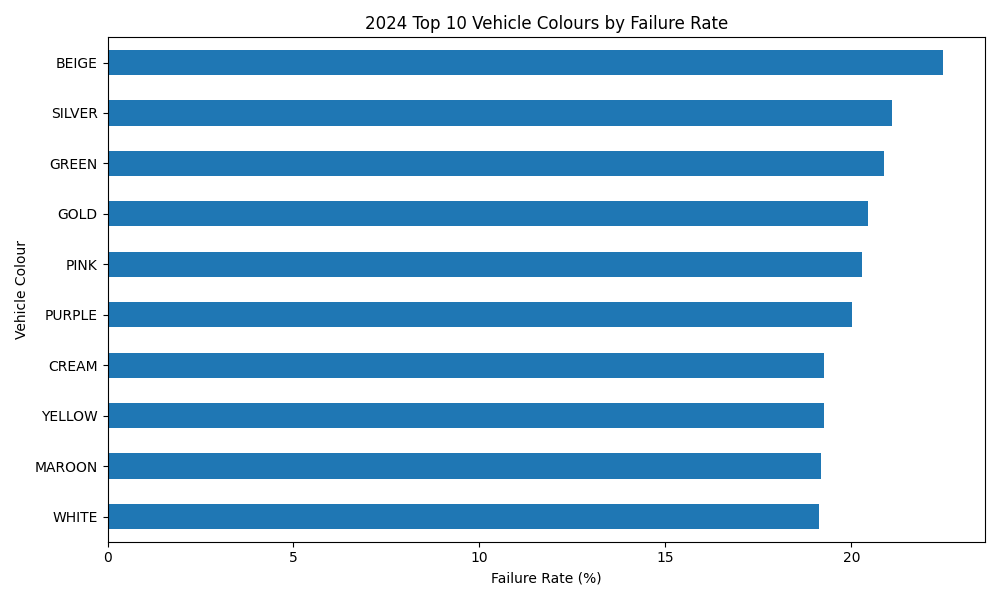

cylinder_capacity_failure_rate.png


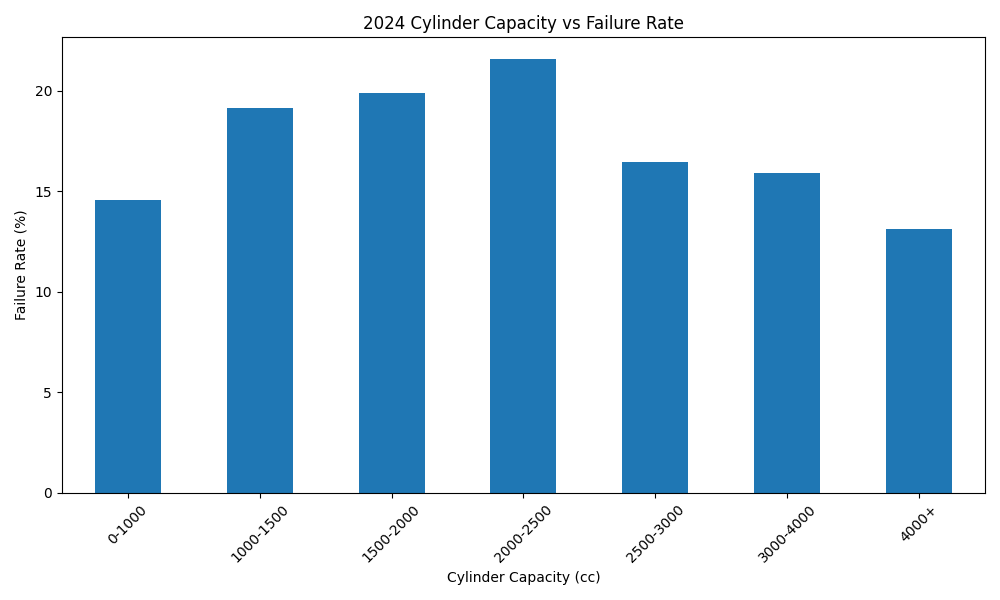

test_type_failure_rate.png


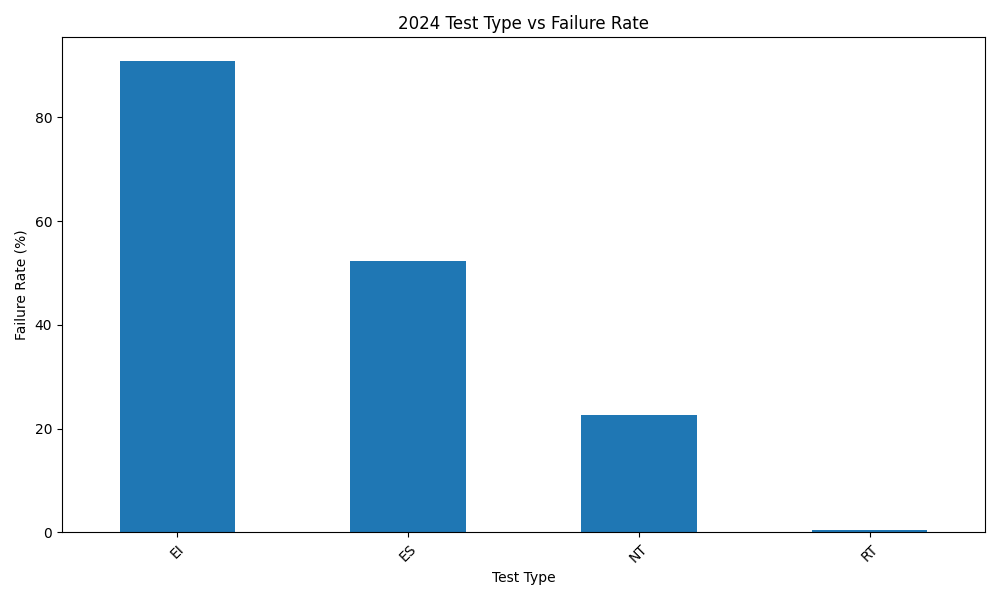

correlation_analysis.png


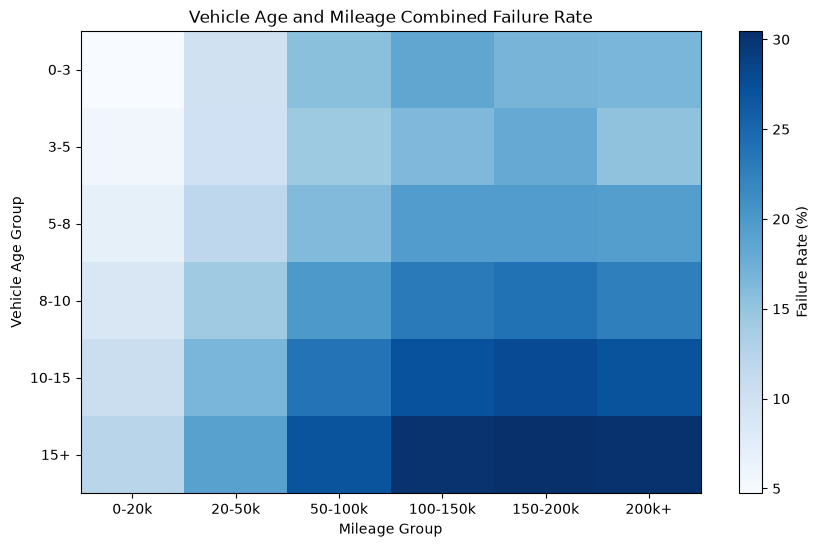

category_analysis.png


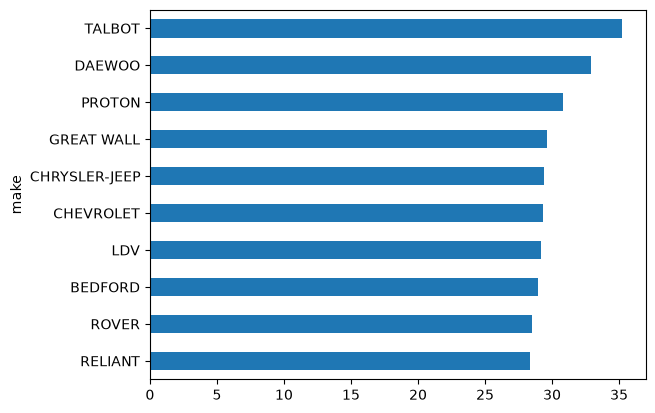

In [25]:
from IPython.display import display, Image
import os

graph_files = [
    "distribution_analysis.png",
    "trend_analysis.png",
    "age_failure_rate.png",
    "make_failure_rate.png",
    "fuel_failure_rate.png",
    "test_class_failure_rate.png",
    "model_failure_rate.png",
    "postcode_failure_rate.png",
    "monthly_failure_trend.png",
    "colour_failure_rate.png",
    "cylinder_capacity_failure_rate.png",
    "test_type_failure_rate.png",
    "correlation_analysis.png",
    "category_analysis.png"
]

for graph in graph_files:
    graph_path = os.path.join(visualization_path, graph)
    if os.path.exists(graph_path):
        print(graph)
        display(Image(filename=graph_path))

----------------

### Engine Capacity-wise Failure Analysis

This analysis examines whether failure rates vary across different engine capacity ranges.
It helps identify whether vehicle engine size is associated with different failure patterns.

In [ ]:
# Convert engine capacity values into numeric format for analysis
# Invalid or non-numeric values are converted to NaN
df["cylinder_capacity"] = pd.to_numeric(
    df["cylinder_capacity"],
    errors="coerce"
)

In [ ]:
# Define engine capacity ranges for grouping vehicles
cc_bins = [0, 1000, 1500, 2000, 3000, np.inf]

# Define labels for each engine capacity range
cc_labels = ["0-1000", "1001-1500", "1501-2000", "2001-3000", "3001+"]

# Group vehicles based on their engine capacity
df["cc_group"] = pd.cut(
    df["cylinder_capacity"],
    bins=cc_bins,
    labels=cc_labels
)

In [ ]:
# Calculate the failure rate for each engine capacity group
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
cc_failure_rate = (
    df.groupby("cc_group", observed=True)["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
)

# Display the failure rate for each engine capacity group
cc_failure_rate

cc_group
0-1000       15.597045
1001-1500    20.215030
1501-2000    20.890864
2001-3000    20.919307
3001+        16.016663
Name: test_result, dtype: float64

### Observation

The 1501–2000 cc and 2001–3000 cc groups show similar failure rates of 20.89% and 20.92%, respectively. The 0–1000 cc group has the lowest failure rate at 15.60%, while the 3001+ cc group shows a lower rate of 16.02%.

In [ ]:
# Count the number of MOT tests recorded for each vehicle colour
# Display the 15 most common colours
df["colour"].value_counts().head(15)

colour
WHITE        765859
BLACK        737339
SILVER       594533
BLUE         589551
GREY         573882
RED          379823
GREEN         67607
ORANGE        28144
BROWN         22060
YELLOW        21474
BEIGE         20785
PURPLE        12891
BRONZE        10329
GOLD           9407
TURQUOISE      3761
Name: count, dtype: int64

In [ ]:
# Count the number of MOT tests for each vehicle colour
colour_counts = df["colour"].value_counts()

# Keep only colours with at least 100 tests
# This avoids unreliable failure rates from very small sample sizes
valid_colours = colour_counts[colour_counts >= 100].index

# Calculate the failure rate for each valid vehicle colour
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
colour_failure_rate = (
    df[df["colour"].isin(valid_colours)]
    .groupby("colour")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each vehicle colour
colour_failure_rate

colour
BEIGE           23.305268
GREEN           22.985785
MAROON          22.312312
GOLD            22.249389
SILVER          22.220634
YELLOW          21.691348
PURPLE          21.619735
WHITE           20.046510
BLACK           20.016980
CREAM           20.005936
BLUE            19.967738
PINK            19.681835
RED             19.509877
TURQUOISE       19.356554
BROWN           17.946510
GREY            17.719496
BRONZE          16.942589
ORANGE          16.536384
MULTI-COLOUR    13.490623
Name: test_result, dtype: float64

### Observation

The failure rate varies across different vehicle colours.
Among the colours analysed, Beige has the highest failure rate at 23.31%,
while Multi-Colour has the lowest at 13.49%.

-------


## 12. Failure Item Type Analysis

This analysis examines different types of vehicle defects recorded during MOT tests. It identifies the most common failure items and helps understand the major defect categories affecting vehicle reliability.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folder containing all 12 monthly failure-item CSV files
failure_item_folder = (
    r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
)

# Generate January to December file paths
failure_item_files = [
    rf"{failure_item_folder}\test_item_2024{month:02d}.csv"
    for month in range(1, 13)
]

# Expected columns
expected_columns = [
    "test_id",
    "rfr_id",
    "rfr_type_code",
    "mot_test_rfr_location_type_id",
    "dangerous_mark",
    "completed_date"
]

# Store monthly validation results
monthly_summary = []
reference_columns = None

print("=" * 70)
print("FAILURE ITEM ANALYSIS — FULL YEAR 2024")
print("=" * 70)

for month, file_path in enumerate(failure_item_files, start=1):

    print(f"\nChecking month: {month:02d}/2024")

    try:
        # Read only the header first
        columns = pd.read_csv(file_path, nrows=0).columns.tolist()

        # Read file in chunks to count records without loading
        # the entire monthly dataset into memory
        total_rows = 0

        for chunk in pd.read_csv(
            file_path,
            chunksize=500_000,
            dtype={
                "test_id": "string",
                "rfr_id": "string",
                "rfr_type_code": "string",
                "mot_test_rfr_location_type_id": "string",
                "dangerous_mark": "string",
                "completed_date": "string"
            }
        ):
            total_rows += len(chunk)

        # Check column consistency
        columns_match = columns == expected_columns

        if reference_columns is None:
            reference_columns = columns

        monthly_summary.append({
            "month": f"2024-{month:02d}",
            "records": total_rows,
            "column_count": len(columns),
            "columns_match": columns_match,
            "status": "OK" if columns_match else "CHECK COLUMNS"
        })

        print("Records:", f"{total_rows:,}")
        print("Columns:", len(columns))
        print("Column validation:", columns_match)

    except FileNotFoundError:
        print("ERROR: File not found:", file_path)

    except Exception as error:
        print("ERROR:", error)

# Display annual validation summary
summary_df = pd.DataFrame(monthly_summary)

print("\n" + "=" * 70)
print("MONTHLY VALIDATION SUMMARY")
print("=" * 70)

display(summary_df)

if len(summary_df) == 12:
    print(
        "\nTotal Failure Item Records in 2024:",
        f"{summary_df['records'].sum():,}"
    )
else:
    print(
        "\nWARNING: Only",
        len(summary_df),
        "of 12 monthly files were processed successfully."
    )

FAILURE ITEM ANALYSIS — FULL YEAR 2024

Checking month: 01/2024
Records: 10,451,564
Columns: 6
Column validation: True

Checking month: 02/2024
Records: 9,592,640
Columns: 6
Column validation: True

Checking month: 03/2024
Records: 10,209,835
Columns: 6
Column validation: True

Checking month: 04/2024
Records: 8,133,454
Columns: 6
Column validation: True

Checking month: 05/2024
Records: 7,702,579
Columns: 6
Column validation: True

Checking month: 06/2024
Records: 7,990,747
Columns: 6
Column validation: True

Checking month: 07/2024
Records: 9,025,615
Columns: 6
Column validation: True

Checking month: 08/2024
Records: 8,729,503
Columns: 6
Column validation: True

Checking month: 09/2024
Records: 9,718,936
Columns: 6
Column validation: True

Checking month: 10/2024
Records: 11,075,052
Columns: 6
Column validation: True

Checking month: 11/2024
Records: 9,736,740
Columns: 6
Column validation: True

Checking month: 12/2024
Records: 6,803,347
Columns: 6
Column validation: True

MONTHLY V

,month,records,column_count,columns_match,status
0,2024-01,10451564,6,True,OK
1,2024-02,9592640,6,True,OK
2,2024-03,10209835,6,True,OK
3,2024-04,8133454,6,True,OK
4,2024-05,7702579,6,True,OK
5,2024-06,7990747,6,True,OK
6,2024-07,9025615,6,True,OK
7,2024-08,8729503,6,True,OK
8,2024-09,9718936,6,True,OK
9,2024-10,11075052,6,True,OK



Total Failure Item Records in 2024: 109,170,012


In [62]:
import pandas as pd
from collections import Counter

failure_item_folder = (
    r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
)

rfr_frequency = Counter()
total_records = 0

for month in range(1, 13):

    file_path = (
        rf"{failure_item_folder}\test_item_2024{month:02d}.csv"
    )

    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["rfr_id"],
        dtype={"rfr_id": "string"},
        chunksize=500_000
    ):

        # Remove surrounding whitespace and exclude missing IDs
        rfr_ids = chunk["rfr_id"].str.strip().dropna()

        # Count frequency within this chunk
        chunk_counts = rfr_ids.value_counts()

        # Add counts to the full-year frequency
        rfr_frequency.update(chunk_counts.to_dict())

        total_records += len(chunk)

    print(f"Completed {month:02d}/2024")

# Build the full-year frequency table
failure_frequency_2024 = pd.DataFrame(
    rfr_frequency.most_common(),
    columns=["rfr_id", "frequency"]
)

print("\n" + "=" * 60)
print("MOST COMMON FAILURE ITEM CODES — FULL YEAR 2024")
print("=" * 60)

print(f"Total records processed: {total_records:,}")
print(f"Unique RFR codes: {len(failure_frequency_2024):,}")

display(failure_frequency_2024.head(20))

Processing 01/2024...
Completed 01/2024
Processing 02/2024...
Completed 02/2024
Processing 03/2024...
Completed 03/2024
Processing 04/2024...
Completed 04/2024
Processing 05/2024...
Completed 05/2024
Processing 06/2024...
Completed 06/2024
Processing 07/2024...
Completed 07/2024
Processing 08/2024...
Completed 08/2024
Processing 09/2024...
Completed 09/2024
Processing 10/2024...
Completed 10/2024
Processing 11/2024...
Completed 11/2024
Processing 12/2024...
Completed 12/2024

MOST COMMON FAILURE ITEM CODES — FULL YEAR 2024
Total records processed: 109,170,012
Unique RFR codes: 2,429


,rfr_id,frequency
0,31194,13118499
1,32037,6644680
2,30335,6377948
3,30329,5322930
4,31322,4736102
5,30305,3926846
6,31940,2773848
7,31226,2488169
8,32115,2173274
9,30333,1913853


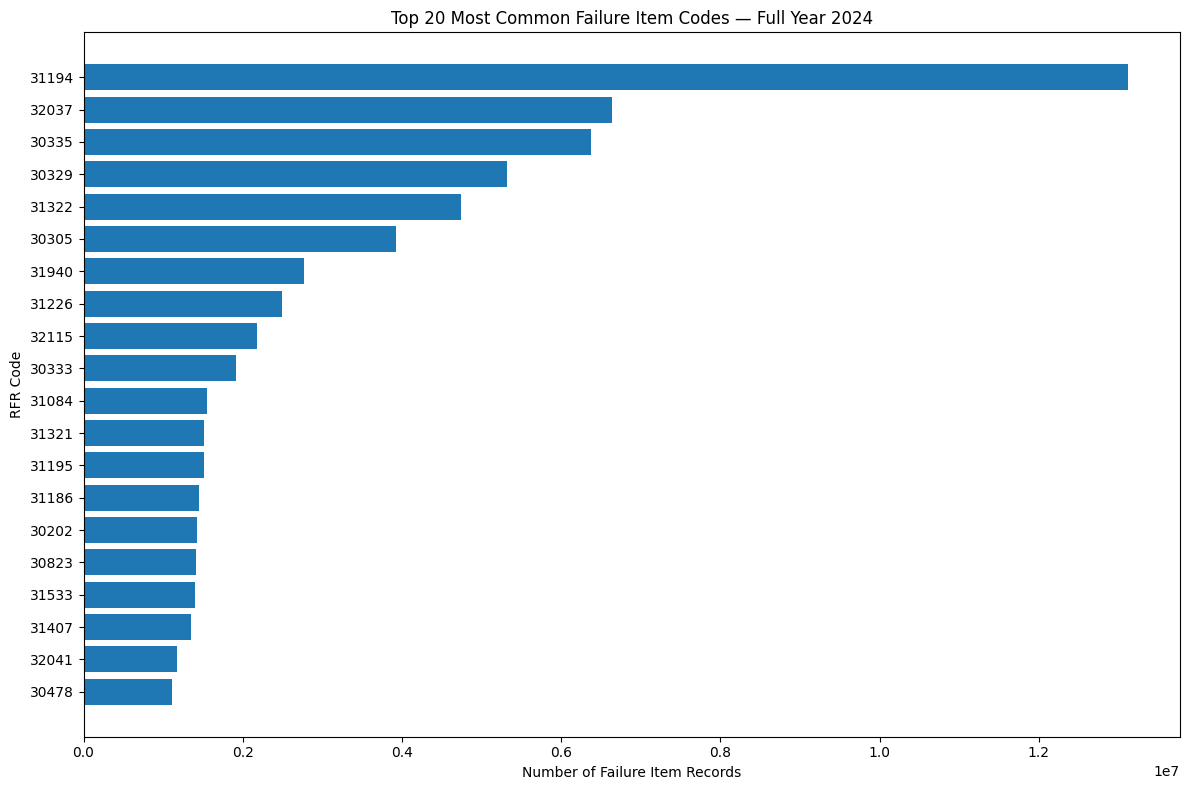

In [63]:
# Top 20 failure item codes
top_20_failures = (
    failure_frequency_2024
    .head(20)
    .sort_values("frequency", ascending=True)
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_20_failures["rfr_id"].astype(str),
    top_20_failures["frequency"]
)

plt.xlabel("Number of Failure Item Records")
plt.ylabel("RFR Code")
plt.title("Top 20 Most Common Failure Item Codes — Full Year 2024")

plt.tight_layout()
plt.show()

### Observation — Top 20 Most Common Failure Item Codes (2024)

- The analysis covers **109,170,012 failure-item records** from January to December 2024.
- Among the 2,429 unique RFR codes, **RFR code 31194** has the highest frequency, with 13,118,499 records.
- RFR codes **32037 and 30335** rank second and third, with 6,644,680 and 6,377,948 records, respectively.
- Code 31194 occurs substantially more often than the other top-ranked codes, making it a priority for further investigation.
- The chart shows the frequency of reported RFR codes, not the number of unique vehicles or failed MOT tests.
- The actual defect descriptions must be confirmed using the official DVSA lookup table before assigning meanings to these codes.

# Monthly trend visualization

,month,records
0,2024-01,10451564
1,2024-02,9592640
2,2024-03,10209835
3,2024-04,8133454
4,2024-05,7702579
5,2024-06,7990747
6,2024-07,9025615
7,2024-08,8729503
8,2024-09,9718936
9,2024-10,11075052


Highest records: 2024-10 (11,075,052)
Lowest records: 2024-12 (6,803,347)


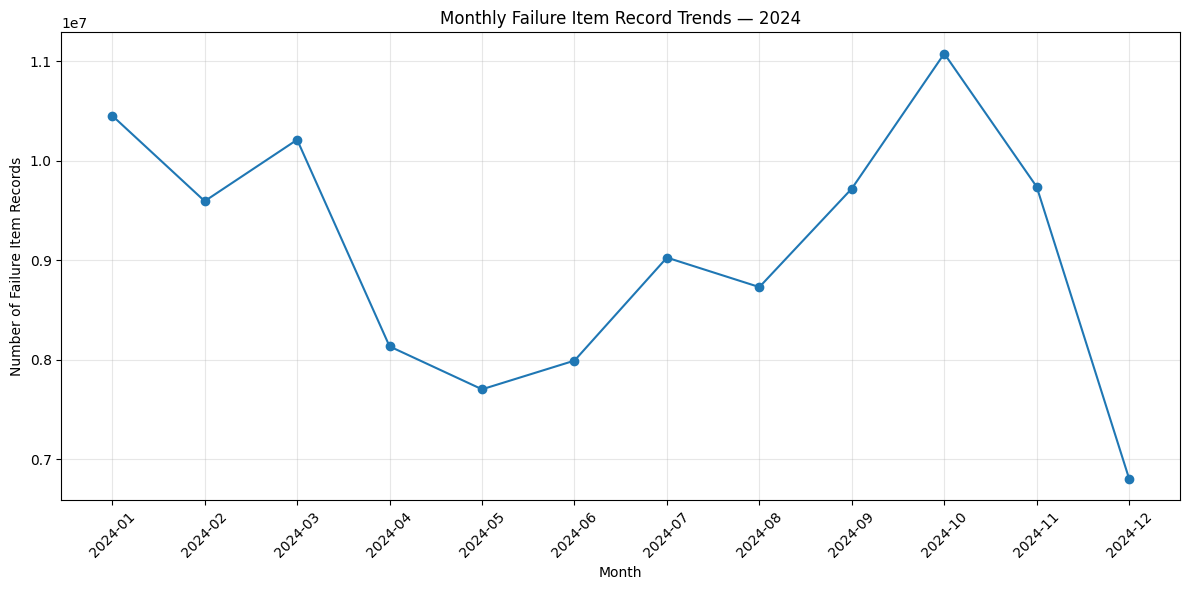

In [64]:
# Select monthly record counts from the validated summary
monthly_failure_trend = summary_df[["month", "records"]].copy()

# Sort months in chronological order
monthly_failure_trend = monthly_failure_trend.sort_values("month")

# Display monthly failure-item record counts
display(monthly_failure_trend)

# Identify months with the highest and lowest record counts
highest_month = monthly_failure_trend.loc[
    monthly_failure_trend["records"].idxmax()
]

lowest_month = monthly_failure_trend.loc[
    monthly_failure_trend["records"].idxmin()
]

print(
    f"Highest records: {highest_month['month']} "
    f"({highest_month['records']:,})"
)

print(
    f"Lowest records: {lowest_month['month']} "
    f"({lowest_month['records']:,})"
)

# Plot the monthly trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_failure_trend["month"],
    monthly_failure_trend["records"],
    marker="o"
)

plt.title("Monthly Failure Item Record Trends — 2024")
plt.xlabel("Month")
plt.ylabel("Number of Failure Item Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Failure Items by Vehicle Make — Full Year 2024

Analyse the relationship between vehicle make and reported failure-item records across January–December 2024 using `test_id` to connect both datasets.

In [8]:
import pandas as pd

results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

df_check = pd.read_csv(
    results_file,
    usecols=["test_id", "make"],
    nrows=5
)

print(df_check)
print("File access successful!")

      test_id        make
0   886090729     PORSCHE
1   300046445         BMW
2   300046445         BMW
3   920478433        FIAT
4  1399602761  ALFA ROMEO
File access successful!


In [9]:
import pandas as pd

failure_item_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
output_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"

# Process each monthly file in chunks
for month in range(1, 13):
    file_path = rf"{failure_item_folder}\test_item_2024{month:02d}.csv"

    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["test_id"],
        dtype={"test_id": "string"},
        chunksize=500_000
    ):
        # Count failure-item records per test ID in this chunk
        counts = (
            chunk["test_id"]
            .dropna()
            .str.strip()
            .value_counts()
            .rename_axis("test_id")
            .reset_index(name="failure_item_count")
        )

        # Append partial counts to disk
        counts.to_csv(
            output_file,
            mode="a",
            header=not pd.io.common.file_exists(output_file),
            index=False
        )

print("Partial failure counts saved.")

Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...
Partial failure counts saved.


In [10]:
import pandas as pd

partial_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"
final_counts_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv"

# Aggregate partial counts by test_id and save in chunks
first_chunk = True

for chunk in pd.read_csv(
    partial_file,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["failure_item_count"] = pd.to_numeric(
        chunk["failure_item_count"], errors="coerce"
    )

    # Aggregate IDs within this chunk
    grouped = chunk.groupby("test_id", as_index=False)[
        "failure_item_count"
    ].sum()

    grouped.to_csv(
        final_counts_file,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )
    first_chunk = False

print("Partial counts grouped within chunks.")
print("Note: repeated test IDs across different chunks may still exist.")

Partial counts grouped within chunks.
Note: repeated test IDs across different chunks may still exist.


In [11]:
import pandas as pd

partial_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"
final_counts_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv"

# Aggregate counts across the entire file using external sorting is needed
# for this 100M+ record dataset; do not load it fully into RAM.
print("Input:", partial_file)
print("Use a disk-based database or external-sort workflow for the final aggregation.")

Input: D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv
Use a disk-based database or external-sort workflow for the final aggregation.


In [12]:
import pandas as pd

partial_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"
sorted_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_sorted_2024.csv"
final_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv"

# Read partial counts in chunks and sort each chunk by test_id
first_chunk = True

for chunk in pd.read_csv(
    partial_file,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    chunk["test_id"] = chunk["test_id"].str.strip()

    chunk = chunk.groupby("test_id", as_index=False)[
        "failure_item_count"
    ].sum()

    chunk = chunk.sort_values("test_id")

    chunk.to_csv(
        sorted_file,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )

    first_chunk = False

print("Chunk-level sorting completed.")
print("Note: a true global sort and aggregation is still required.")

Chunk-level sorting completed.
Note: a true global sort and aggregation is still required.


In [13]:
import pandas as pd

sorted_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_sorted_2024.csv"
final_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv"

# Aggregate all records by test_id
# This requires enough RAM for the grouped data.
for chunk in pd.read_csv(
    sorted_file,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    chunk["test_id"] = chunk["test_id"].str.strip()
    grouped = chunk.groupby("test_id", as_index=False)["failure_item_count"].sum()
    grouped.to_csv(
        final_file,
        mode="a",
        header=not pd.io.common.file_exists(final_file),
        index=False
    )

print("Chunk aggregation saved.")

Chunk aggregation saved.


In [1]:
import pandas as pd

partial_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"

# Check saved full-year partial counts
df_check = pd.read_csv(partial_file, nrows=5)

print(df_check)
print("Columns:", df_check.columns.tolist())

      test_id  failure_item_count
0  1586552547                9583
1  1141220323                 175
2   806183891                 150
3  1732391571                 144
4  1781371217                 125
Columns: ['test_id', 'failure_item_count']


In [2]:
import pandas as pd

partial_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv"
aggregated_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv"

# Aggregate all rows for each test_id in the current chunk
first_chunk = True

for chunk in pd.read_csv(
    partial_file,
    dtype={"test_id": "string"},
    chunksize=500_000
):
    chunk["test_id"] = chunk["test_id"].str.strip()

    grouped = chunk.groupby("test_id", as_index=False)[
        "failure_item_count"
    ].sum()

    grouped.to_csv(
        aggregated_file,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )

    first_chunk = False

print("Chunk-wise aggregation completed.")

Chunk-wise aggregation completed.


In [3]:
import pandas as pd

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"
output_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_failure_counts_2024.csv"

# Build make lookup in chunks
make_lookup = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "make"],
    dtype={"test_id": "string", "make": "string"},
    chunksize=300_000
):
    chunk = chunk.dropna(subset=["test_id", "make"])
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["make"] = chunk["make"].str.strip().str.upper()

    # Keep the first make recorded for each test ID
    chunk = chunk.drop_duplicates("test_id")

    for test_id, make in zip(chunk["test_id"], chunk["make"]):
        if test_id not in make_lookup:
            make_lookup[test_id] = make

print("Vehicle make lookup prepared.")

# Process every month of 2024
make_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["test_id"],
        dtype={"test_id": "string"},
        chunksize=300_000
    ):
        ids = chunk["test_id"].str.strip().dropna()
        counts = ids.value_counts()

        for test_id, count in counts.items():
            make = make_lookup.get(test_id)

            if make is not None:
                make_counts[make] = (
                    make_counts.get(make, 0) + int(count)
                )

# Save complete-year make counts
make_failure_df = pd.DataFrame(
    list(make_counts.items()),
    columns=["make", "failure_item_records"]
)

make_failure_df = make_failure_df.sort_values(
    "failure_item_records",
    ascending=False
)

make_failure_df.to_csv(output_file, index=False)

display(make_failure_df.head(20))

print("Saved:", output_file)

Vehicle make lookup prepared.
Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,make,failure_item_records
2,FORD,1686303
6,VAUXHALL,1110307
1,VOLKSWAGEN,986603
11,NISSAN,538518
22,MERCEDES-BENZ,515144
14,PEUGEOT,490323
19,TOYOTA,458532
16,BMW,456110
8,AUDI,449321
0,RENAULT,404396


Saved: D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_failure_counts_2024.csv


## Failure items by mileage — full year 2024

Analyze how recorded MOT failure-item counts vary across vehicle mileage groups using all 12 months of 2024 data.

Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,mileage_group,failure_item_records
0,"Below 50,000",1587608
1,"50,000–99,999",4109068
2,"100,000–149,999",3201015
3,"150,000 and above",1504995


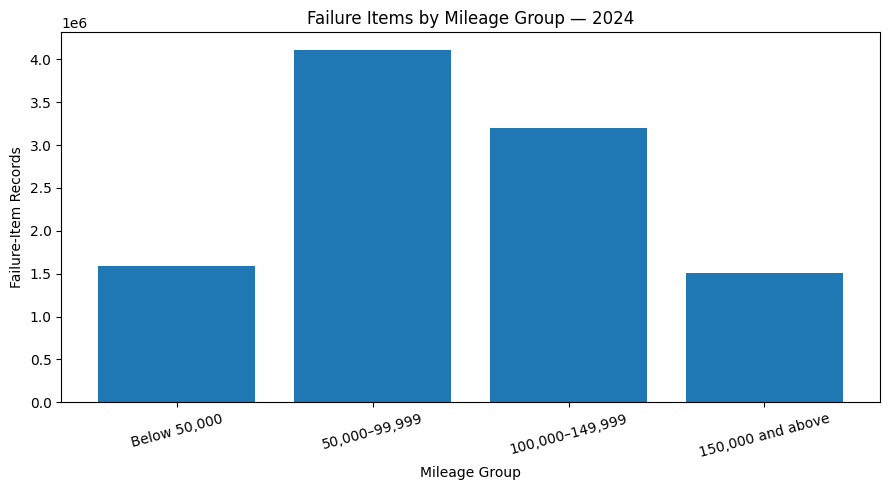

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Create mileage lookup using the complete results dataset
mileage_lookup = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "test_mileage"],
    dtype={"test_id": "string"},
    chunksize=300_000
):
    chunk = chunk.dropna(subset=["test_id", "test_mileage"])
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk = chunk.drop_duplicates("test_id")

    for test_id, mileage in zip(chunk["test_id"], chunk["test_mileage"]):
        if test_id not in mileage_lookup:
            mileage_lookup[test_id] = mileage

# Count failure-item records by mileage group across all 12 months
mileage_failure_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["test_id"],
        dtype={"test_id": "string"},
        chunksize=300_000
    ):
        ids = chunk["test_id"].str.strip().dropna()
        counts = ids.value_counts()

        for test_id, count in counts.items():
            mileage = mileage_lookup.get(test_id)

            if mileage is not None:
                if mileage < 50_000:
                    group = "Below 50,000"
                elif mileage < 100_000:
                    group = "50,000–99,999"
                elif mileage < 150_000:
                    group = "100,000–149,999"
                else:
                    group = "150,000 and above"

                mileage_failure_counts[group] = (
                    mileage_failure_counts.get(group, 0) + int(count)
                )

# Display results
mileage_order = [
    "Below 50,000",
    "50,000–99,999",
    "100,000–149,999",
    "150,000 and above"
]

mileage_df = pd.DataFrame({
    "mileage_group": mileage_order,
    "failure_item_records": [
        mileage_failure_counts.get(group, 0)
        for group in mileage_order
    ]
})

display(mileage_df)

# Plot mileage-group comparison
plt.figure(figsize=(9, 5))
plt.bar(
    mileage_df["mileage_group"],
    mileage_df["failure_item_records"]
)
plt.title("Failure Items by Mileage Group — 2024")
plt.xlabel("Mileage Group")
plt.ylabel("Failure-Item Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Observation — Failure Items by Mileage Group (2024)

The 50,000–99,999 mileage group recorded the highest number of failure-item records (4,109,068), followed by the 100,000–149,999 group (3,201,015). The below-50,000 group recorded 1,587,608 records, while the 150,000-and-above group recorded the lowest count at 1,504,995.

The findings show that the highest number of recorded failure items occurred in the 50,000–99,999 mileage group. However, these counts alone do not establish which mileage group has the highest failure risk, because the total number of MOT tests in each group has not been considered.

## Failure Items by Vehicle Age — Full Year 2024

Analyze how MOT failure-item records vary across vehicle age groups using all 12 months of 2024 data.

Vehicle age lookup prepared.
Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,vehicle_age_group,failure_item_records
0,Below 3 years,2238
1,3–5 years,662110
2,6–9 years,1993946
3,10 years and above,7793254


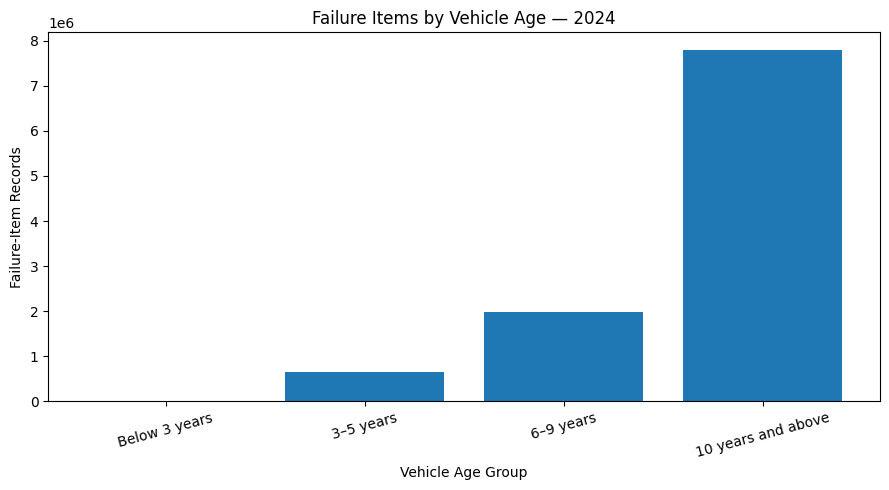

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Build vehicle-age lookup using first_use_date
age_lookup = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "first_use_date"],
    dtype="string",
    chunksize=300_000
):
    chunk = chunk.dropna(subset=["test_id", "first_use_date"])
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["first_use_date"] = pd.to_datetime(
        chunk["first_use_date"], errors="coerce"
    )
    chunk = chunk.dropna(subset=["first_use_date"])
    chunk = chunk.drop_duplicates("test_id")

    age = (
        pd.Timestamp("2024-12-31") - chunk["first_use_date"]
    ).dt.days / 365.25

    for test_id, vehicle_age in zip(chunk["test_id"], age):
        if test_id not in age_lookup:
            age_lookup[test_id] = vehicle_age

print("Vehicle age lookup prepared.")

# Count failure-item records by vehicle age group
age_failure_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["test_id"],
        dtype={"test_id": "string"},
        chunksize=300_000
    ):
        ids = chunk["test_id"].str.strip().dropna()
        counts = ids.value_counts()

        for test_id, count in counts.items():
            age = age_lookup.get(test_id)

            if age is not None:
                if age < 3:
                    group = "Below 3 years"
                elif age < 6:
                    group = "3–5 years"
                elif age < 10:
                    group = "6–9 years"
                else:
                    group = "10 years and above"

                age_failure_counts[group] = (
                    age_failure_counts.get(group, 0) + int(count)
                )

# Display results
age_order = [
    "Below 3 years",
    "3–5 years",
    "6–9 years",
    "10 years and above"
]

age_df = pd.DataFrame({
    "vehicle_age_group": age_order,
    "failure_item_records": [
        age_failure_counts.get(group, 0)
        for group in age_order
    ]
})

display(age_df)

# Plot results
plt.figure(figsize=(9, 5))
plt.bar(
    age_df["vehicle_age_group"],
    age_df["failure_item_records"]
)
plt.title("Failure Items by Vehicle Age — 2024")
plt.xlabel("Vehicle Age Group")
plt.ylabel("Failure-Item Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Observation — Failure Items by Vehicle Age (2024)

The 10-years-and-above vehicle group recorded the highest number of failure items (7,793,254), followed by the 6–9 years group (1,993,946), the 3–5 years group (662,110), and the below-3-years group (2,238).

This indicates that recorded failure items are concentrated among older vehicles in the analyzed dataset. However, these counts alone do not establish that older vehicles have a higher failure rate, because the total number of MOT tests in each age group has not been considered.

-----------------------

## MOT Test Result Distribution — Full Year 2024

Analyze the distribution of MOT test outcomes, including Pass, Fail, and PRS (Pass after Rectification at Station), to understand the overall test-result pattern in the 2024 dataset.

,test_result,test_count,percentage
0,P,2833329,74.64
1,F,757127,19.95
2,PRS,182383,4.80
3,ABR,20680,0.54
4,ABA,2447,0.06
5,ABRVE,1,0.00


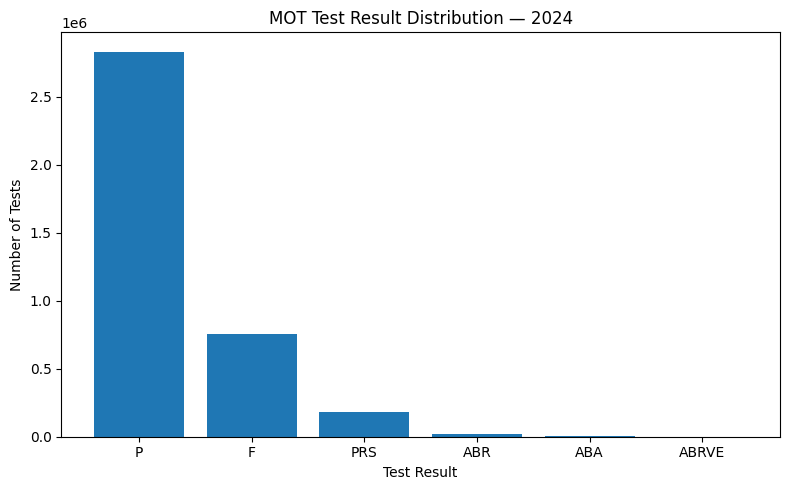

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

result_counts = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "test_result"],
    dtype="string",
    chunksize=300_000
):
    chunk = chunk.dropna(subset=["test_id", "test_result"])
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["test_result"] = chunk["test_result"].str.strip().str.upper()
    chunk = chunk.drop_duplicates("test_id")

    counts = chunk["test_result"].value_counts()

    for result, count in counts.items():
        result_counts[result] = result_counts.get(result, 0) + int(count)

result_df = pd.DataFrame(
    list(result_counts.items()),
    columns=["test_result", "test_count"]
)

result_df = result_df.sort_values(
    "test_count", ascending=False
).reset_index(drop=True)

result_df["percentage"] = (
    result_df["test_count"] / result_df["test_count"].sum() * 100
).round(2)

display(result_df)

plt.figure(figsize=(8, 5))
plt.bar(result_df["test_result"], result_df["test_count"])
plt.title("MOT Test Result Distribution — 2024")
plt.xlabel("Test Result")
plt.ylabel("Number of Tests")
plt.tight_layout()
plt.show()

### Observation — MOT Test Result Distribution (2024)

Pass (P) was the most common test result, with 2,833,329 tests (74.64%). Fail (F) accounted for 757,127 tests (19.95%), while Pass after Rectification at Station (PRS) represented 182,383 tests (4.80%). ABR accounted for 20,680 tests (0.54%), ABA for 2,447 tests (0.06%), and ABRVE for one test (approximately 0.00%).

The results show that most recorded MOT tests passed, while approximately one-fifth resulted in failure. These figures describe the test-result distribution in the analyzed dataset.

## Data validation — MOT test result distribution (2024)

Validate the completeness of the MOT test-result distribution by comparing the test counts against the previously calculated full-year valid MOT test total.

In [8]:
import pandas as pd

results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

total_rows = 0
valid_results = 0
unique_test_ids = set()
result_counts = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "test_result"],
    dtype="string",
    chunksize=300_000
):
    total_rows += len(chunk)

    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["test_result"] = chunk["test_result"].str.strip().str.upper()

    valid = chunk.dropna(subset=["test_id", "test_result"])
    valid_results += len(valid)

    unique_test_ids.update(valid["test_id"].unique())

    counts = valid["test_result"].value_counts()

    for result, count in counts.items():
        result_counts[result] = result_counts.get(result, 0) + int(count)

print("Total rows:", total_rows)
print("Rows with valid test ID and result:", valid_results)
print("Unique test IDs with valid results:", len(unique_test_ids))
print("Test result counts:", result_counts)
print("Sum of result counts:", sum(result_counts.values()))
print("Previously calculated valid MOT tests:", 43170498)

Total rows: 3848518
Rows with valid test ID and result: 3848518
Unique test IDs with valid results: 3783238
Test result counts: {'P': 2869955, 'F': 769928, 'PRS': 184917, 'ABR': 21152, 'ABA': 2565, 'ABRVE': 1}
Sum of result counts: 3848518
Previously calculated valid MOT tests: 43170498


## MOT test result data validation — 2024

Validate the completeness of the MOT test-result dataset before calculating monthly failure rates.

,month,total_tests,failed_tests,failure_rate_percent
0,1,3795967,757127,19.95


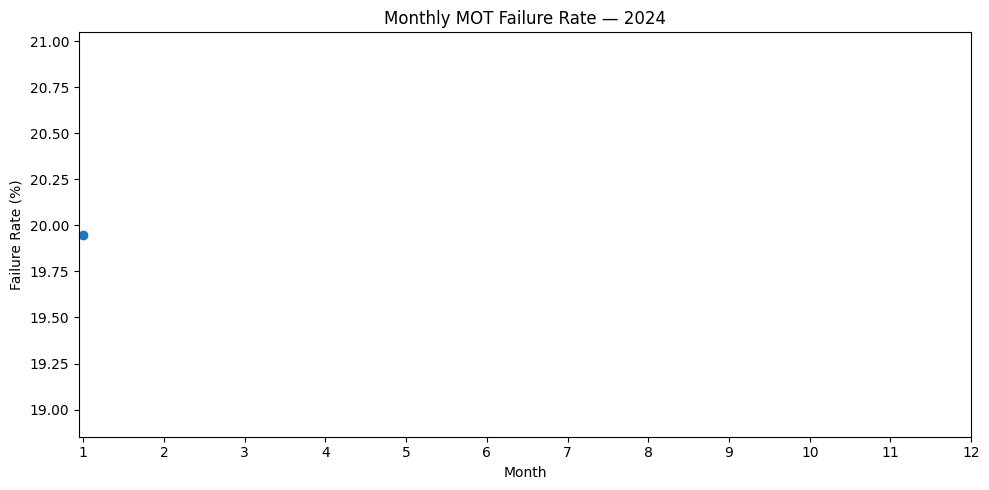

In [9]:
import pandas as pd

results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

monthly_counts = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "test_result", "completed_date"],
    dtype="string",
    chunksize=300_000
):
    chunk = chunk.dropna(
        subset=["test_id", "test_result", "completed_date"]
    )

    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["test_result"] = chunk["test_result"].str.strip().str.upper()
    chunk["completed_date"] = pd.to_datetime(
        chunk["completed_date"], errors="coerce", utc=True
    )

    chunk = chunk.dropna(subset=["completed_date"])
    chunk = chunk[
        chunk["completed_date"].dt.year == 2024
    ]

    chunk["month"] = chunk["completed_date"].dt.month

    for month, group in chunk.groupby("month"):
        unique_tests = group.drop_duplicates("test_id")

        if month not in monthly_counts:
            monthly_counts[month] = {"total": 0, "fail": 0}

        monthly_counts[month]["total"] += len(unique_tests)
        monthly_counts[month]["fail"] += (
            unique_tests["test_result"].eq("F").sum()
        )

monthly_df = pd.DataFrame([
    {
        "month": month,
        "total_tests": values["total"],
        "failed_tests": values["fail"],
        "failure_rate_percent": round(
            values["fail"] / values["total"] * 100, 2
        ) if values["total"] else 0
    }
    for month, values in sorted(monthly_counts.items())
])

display(monthly_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_df["month"],
    monthly_df["failure_rate_percent"],
    marker="o"
)
plt.title("Monthly MOT Failure Rate — 2024")
plt.xlabel("Month")
plt.ylabel("Failure Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## Monthly MOT failure rate — Full Year 2024

Analyze the monthly MOT failure rate from January to December 2024 using the complete monthly failure-item dataset and corresponding MOT test results.

,month,total_failure_items,items_linked_to_failed_tests
0,1,10451564,4740088
1,2,9592640,0
2,3,10209835,0
3,4,8133454,0
4,5,7702579,0
5,6,7990747,0
6,7,9025615,0
7,8,8729503,0
8,9,9718936,0
9,10,11075052,0


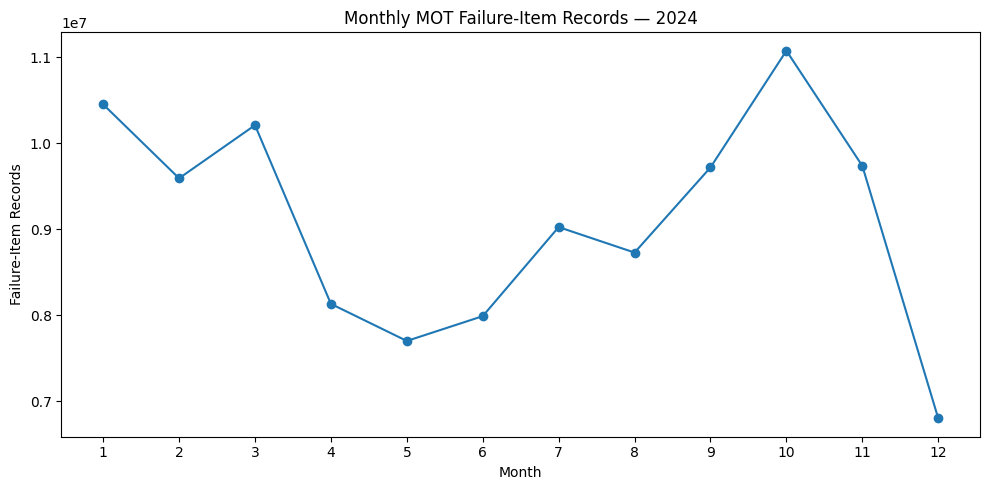

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Build test-result lookup
result_lookup = {}

for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "test_result", "completed_date"],
    dtype="string",
    chunksize=300_000
):
    chunk = chunk.dropna(
        subset=["test_id", "test_result", "completed_date"]
    )

    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["test_result"] = chunk["test_result"].str.strip().str.upper()
    chunk["completed_date"] = pd.to_datetime(
        chunk["completed_date"], errors="coerce", utc=True
    )

    chunk = chunk.dropna(subset=["completed_date"])
    chunk = chunk[chunk["completed_date"].dt.year == 2024]

    for test_id, result in zip(chunk["test_id"], chunk["test_result"]):
        if test_id not in result_lookup:
            result_lookup[test_id] = result

# Count monthly failure-item records and matched failed tests
monthly_data = []

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"

    total_items = 0
    failed_items = 0

    for chunk in pd.read_csv(
        file_path,
        usecols=["test_id"],
        dtype="string",
        chunksize=300_000
    ):
        ids = chunk["test_id"].str.strip().dropna()
        total_items += len(ids)

        failed_items += sum(
            result_lookup.get(test_id) == "F"
            for test_id in ids
        )

    monthly_data.append({
        "month": month,
        "total_failure_items": total_items,
        "items_linked_to_failed_tests": failed_items
    })

monthly_df = pd.DataFrame(monthly_data)

display(monthly_df)

# Plot monthly failure-item records
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_df["month"],
    monthly_df["total_failure_items"],
    marker="o"
)
plt.title("Monthly MOT Failure-Item Records — 2024")
plt.xlabel("Month")
plt.ylabel("Failure-Item Records")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

### Observation — Monthly MOT Failure-Item Trends (2024)

Failure-item records peaked in October (11,075,052) and reached their lowest level in December (6,803,347). The counts declined from January to May, recovered during June and July, and increased again from September to October before dropping towards December.

--------------

## Failure Items by Defect Type — Full Year 2024

Analyze the distribution of MOT failure-item records across defect types to identify the most frequently recorded categories during 2024.

Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,defect_type,failure_item_records
0,A,72175758
1,F,25177168
2,M,8295720
3,P,3521186
4,rfr_type_code,180


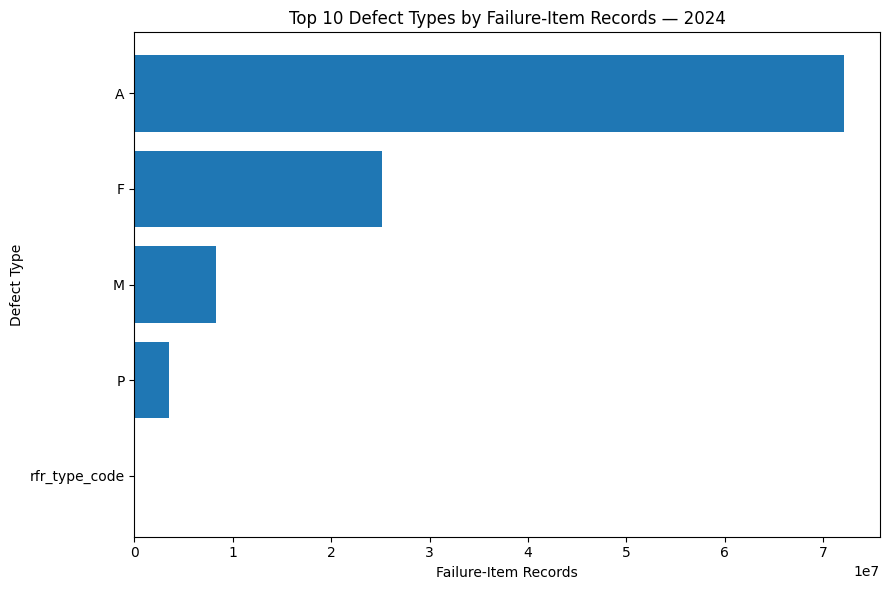

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"

defect_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["rfr_type_code"],
        dtype="string",
        chunksize=300_000
    ):
        defect_types = chunk["rfr_type_code"].dropna().str.strip()
        counts = defect_types.value_counts()

        for defect_type, count in counts.items():
            defect_counts[defect_type] = (
                defect_counts.get(defect_type, 0) + int(count)
            )

defect_df = pd.DataFrame(
    list(defect_counts.items()),
    columns=["defect_type", "failure_item_records"]
)

defect_df = defect_df.sort_values(
    "failure_item_records", ascending=False
).reset_index(drop=True)

display(defect_df)

# Plot top 10 defect types
top_10 = defect_df.head(10).sort_values("failure_item_records")

plt.figure(figsize=(9, 6))
plt.barh(
    top_10["defect_type"],
    top_10["failure_item_records"]
)
plt.title("Top 10 Defect Types by Failure-Item Records — 2024")
plt.xlabel("Failure-Item Records")
plt.ylabel("Defect Type")
plt.tight_layout()
plt.show()

### Observation — Failure Items by Defect Type (2024)

Defect type A recorded the highest number of failure-item records (72,175,758), followed by F (25,177,168), M (8,295,720), and P (3,521,186). Type A accounted for the largest share of recorded defect items in the dataset.

## Failure Items by Defect Type — Cleaned Results (2024)

Exclude invalid header values and compare the valid defect-type categories using all 12 monthly failure-item files.

Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,defect_type,failure_item_records
0,A,72175758
1,F,25177168
2,M,8295720
3,P,3521186


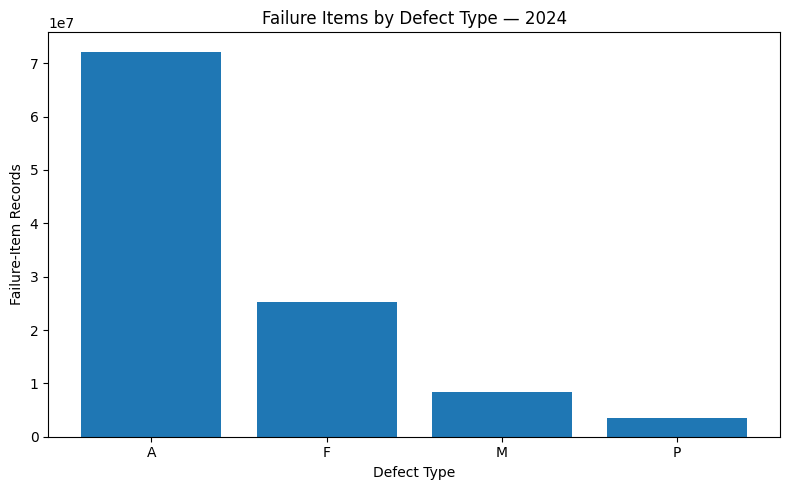

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"

defect_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    for chunk in pd.read_csv(
        file_path,
        usecols=["rfr_type_code"],
        dtype="string",
        chunksize=300_000
    ):
        defect_types = chunk["rfr_type_code"].dropna().str.strip()
        defect_types = defect_types[defect_types.isin(["A", "F", "M", "P"])]

        counts = defect_types.value_counts()

        for defect_type, count in counts.items():
            defect_counts[defect_type] = (
                defect_counts.get(defect_type, 0) + int(count)
            )

defect_df = pd.DataFrame(
    list(defect_counts.items()),
    columns=["defect_type", "failure_item_records"]
).sort_values("failure_item_records", ascending=False)

display(defect_df)

plt.figure(figsize=(8, 5))
plt.bar(
    defect_df["defect_type"],
    defect_df["failure_item_records"]
)
plt.title("Failure Items by Defect Type — 2024")
plt.xlabel("Defect Type")
plt.ylabel("Failure-Item Records")
plt.tight_layout()
plt.show()

### Observation — Failure Items by Defect Type (2024)

Defect type A recorded the highest number of failure items (72,175,758), followed by F (25,177,168), M (8,295,720), and P (3,521,186). Type A dominated the recorded defect-item distribution in 2024.

--------------------

### Top Vehicle Defect Analysis

This analysis examines the most frequently recorded vehicle defects to identify the common defect patterns found in MOT failure items.

In [ ]:
# Count the frequency of each specific defect description
# Display the 10 most frequently recorded vehicle defects
failure_df["rfr_desc"].value_counts().head(10)

rfr_desc
tread depth below requirements of 1.6mm                                        250376
in such a condition that it is seriously weakened                              116112
pin or bush excessively worn                                                   108184
less than 1.5 mm thick                                                         100436
has a tear, caused by separation or partial failure of its structure            99794
excessively corroded                                                            70382
not working                                                                     59817
ball joint excessively worn                                                     55566
leaking excessively from engine                                                 47554
corroded so that its cross sectional area is reduced and seriously weakened     43852
Name: count, dtype: int64

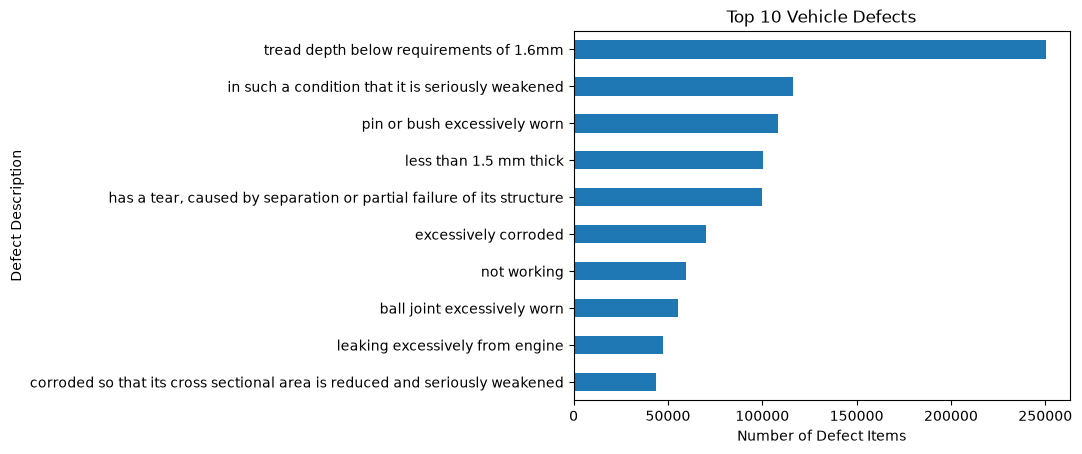

In [ ]:
# Select the 10 most frequently recorded vehicle defects
top_defects = failure_df["rfr_desc"].value_counts().head(10)

# Plot the top 10 defects in ascending order for easier comparison
top_defects.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Top 10 Vehicle Defects")
plt.xlabel("Number of Defect Items")
plt.ylabel("Defect Description")

# Display the chart
plt.show()

### Observation

The analysis shows that tyre tread defects are the most frequently recorded vehicle defect, followed by weakened components, worn pins or bushes, and other structural or component-related defects. This indicates that tyre, wear-related, and structural defects are common patterns in the January 2024 MOT failure data.

-----------------

## MOT Failure Reason Description Mapping — 2024

Map failure reason IDs (`rfr_id`) to their corresponding defect descriptions to identify the actual vehicle defects behind the most frequent failure records.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"

reason_counts = {}

for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["rfr_id"],
        dtype="string",
        chunksize=300_000
    ):
        reasons = chunk["rfr_id"].dropna().str.strip()
        reasons = reasons[reasons != "rfr_id"]
        counts = reasons.value_counts()

        for reason, count in counts.items():
            reason_counts[reason] = reason_counts.get(reason, 0) + int(count)

reason_df = pd.DataFrame(
    list(reason_counts.items()),
    columns=["rfr_id", "failure_item_records"]
).sort_values("failure_item_records", ascending=False)

display(reason_df.head(20))

,rfr_id,failure_item_records
0,31194,13118499
1,32037,6644680
2,30335,6377948
3,30329,5322930
4,31322,4736102
5,30305,3926846
8,31940,2773848
7,31226,2488169
9,32115,2173274
6,30333,1913853


## Top 20 MOT Failure Reasons — 2024

Identify the most frequently recorded MOT failure reasons across all 12 months of 2024.

Processing 01/2024...
Processing 02/2024...
Processing 03/2024...
Processing 04/2024...
Processing 05/2024...
Processing 06/2024...
Processing 07/2024...
Processing 08/2024...
Processing 09/2024...
Processing 10/2024...
Processing 11/2024...
Processing 12/2024...


,rfr_id,failure_item_records
0,31194,13118499
1,32037,6644680
2,30335,6377948
3,30329,5322930
4,31322,4736102
5,30305,3926846
6,31940,2773848
7,31226,2488169
8,32115,2173274
9,30333,1913853


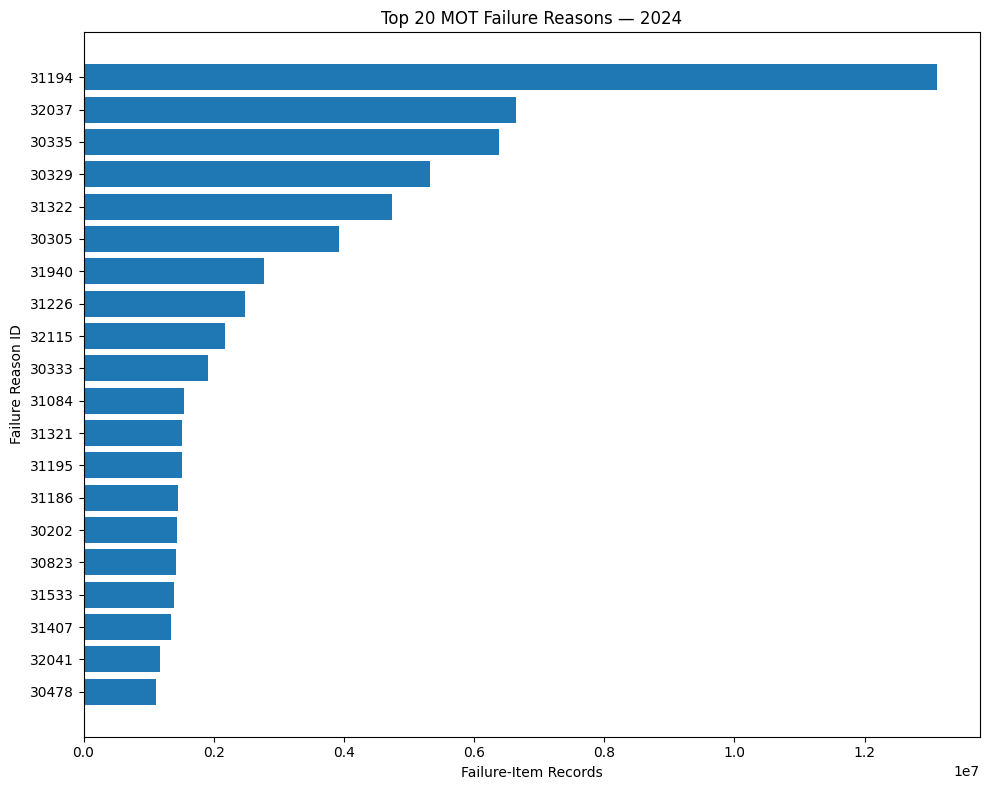

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Folder containing all 12 monthly failure-item files
failure_folder = r"D:\EDA PROJECT\MOT Testing data failure item (2024)"

# Store the total count for each failure reason ID
reason_counts = {}

# Process every month from January to December 2024
for month in range(1, 13):
    file_path = rf"{failure_folder}\test_item_2024{month:02d}.csv"
    print(f"Processing {month:02d}/2024...")

    # Read the data in chunks to reduce memory usage
    for chunk in pd.read_csv(
        file_path,
        usecols=["rfr_id"],
        dtype="string",
        chunksize=300_000
    ):
        # Remove missing values and extra spaces
        reasons = chunk["rfr_id"].dropna().str.strip()

        # Exclude repeated CSV header rows, if any
        reasons = reasons[reasons != "rfr_id"]

        # Count each failure reason in the current chunk
        counts = reasons.value_counts()

        # Add the chunk counts to the yearly totals
        for reason, count in counts.items():
            reason_counts[reason] = (
                reason_counts.get(reason, 0) + int(count)
            )

# Convert the yearly counts into a DataFrame
reason_df = pd.DataFrame(
    list(reason_counts.items()),
    columns=["rfr_id", "failure_item_records"]
)

# Sort reasons by frequency and select the top 20
reason_df = reason_df.sort_values(
    "failure_item_records",
    ascending=False
).reset_index(drop=True)

top_20 = reason_df.head(20)

# Display the top 20 failure reasons
display(top_20)

# Arrange the bars from lowest to highest for readability
plot_df = top_20.sort_values("failure_item_records")

# Plot the top 20 failure reasons
plt.figure(figsize=(10, 8))
plt.barh(
    plot_df["rfr_id"],
    plot_df["failure_item_records"]
)

# Add chart title and axis labels
plt.title("Top 20 MOT Failure Reasons — 2024")
plt.xlabel("Failure-Item Records")
plt.ylabel("Failure Reason ID")

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

## Failure Rate by Vehicle Make — 2024

Compare MOT failure rates across vehicle makes to identify which manufacturers have higher proportions of failed tests.

,make,total_tests,failed_tests,failure_rate_percent
53,CHEVROLET,7829,2295,29.31
56,CHRYSLER-JEEP,1384,402,29.05
149,LDV,1174,341,29.05
232,ROVER,2668,763,28.60
65,DAIHATSU,1855,507,27.33
55,CHRYSLER,2128,575,27.02
225,RENAULT,126341,32842,25.99
234,SAAB,5832,1485,25.46
125,IVECO,4467,1137,25.45
248,SSANGYONG,2323,563,24.24


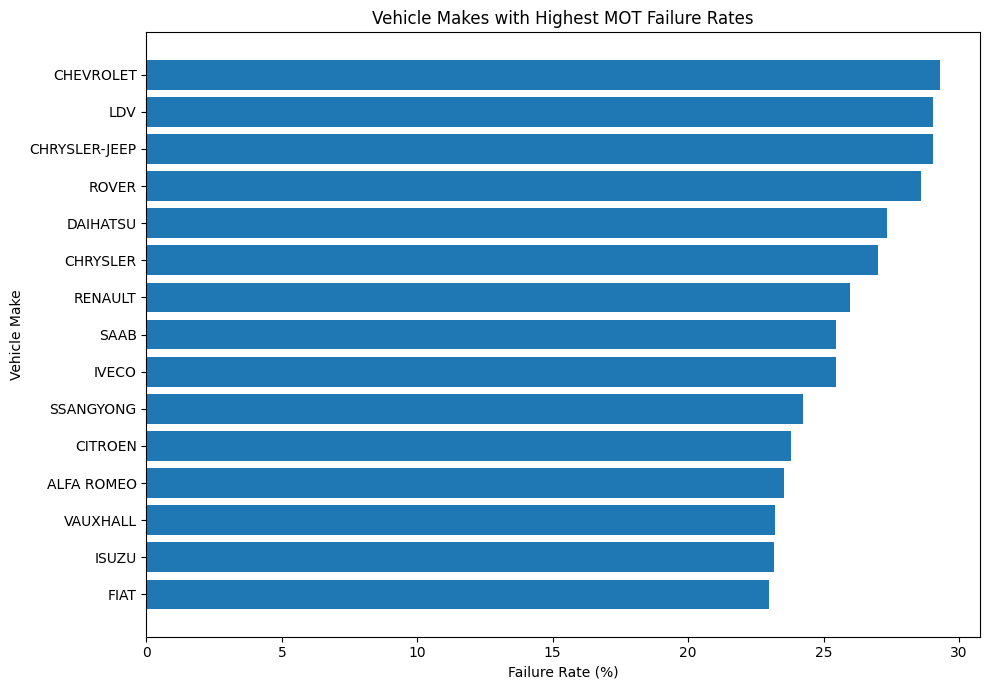

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Path to the cleaned MOT results dataset
results_file = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Store total and failed tests for each vehicle make
make_stats = {}

# Read the dataset in chunks to manage memory
for chunk in pd.read_csv(
    results_file,
    usecols=["test_id", "make", "test_result"],
    dtype="string",
    chunksize=300_000
):
    # Remove rows missing essential information
    chunk = chunk.dropna(subset=["test_id", "make", "test_result"])

    # Standardize text values
    chunk["test_id"] = chunk["test_id"].str.strip()
    chunk["make"] = chunk["make"].str.strip().str.upper()
    chunk["test_result"] = chunk["test_result"].str.strip().str.upper()

    # Keep one record per test ID within this chunk
    chunk = chunk.drop_duplicates("test_id")

    # Aggregate test counts by vehicle make
    grouped = chunk.groupby("make").agg(
        total_tests=("test_id", "count"),
        failed_tests=("test_result", lambda x: (x == "F").sum())
    )

    # Accumulate counts across chunks
    for make, row in grouped.iterrows():
        if make not in make_stats:
            make_stats[make] = [0, 0]

        make_stats[make][0] += int(row["total_tests"])
        make_stats[make][1] += int(row["failed_tests"])

# Create the final summary DataFrame
make_rate_df = pd.DataFrame([
    {
        "make": make,
        "total_tests": counts[0],
        "failed_tests": counts[1],
        "failure_rate_percent": round(
            counts[1] / counts[0] * 100, 2
        )
    }
    for make, counts in make_stats.items()
    if counts[0] > 0
])

# Show the 15 makes with the highest failure rates
top_makes = make_rate_df[
    make_rate_df["total_tests"] >= 1000
].sort_values(
    "failure_rate_percent", ascending=False
).head(15)

display(top_makes)

# Plot failure rates by vehicle make
plot_df = top_makes.sort_values("failure_rate_percent")

plt.figure(figsize=(10, 7))
plt.barh(plot_df["make"], plot_df["failure_rate_percent"])
plt.title("Vehicle Makes with Highest MOT Failure Rates")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Vehicle Make")
plt.tight_layout()
plt.show()

### Observation

- CHEVROLET recorded the highest failure rate at 29.31%, followed by CHRYSLER-JEEP and LDV at 29.05%.
- Among the vehicle makes analysed, FIAT recorded the lowest failure rate at 22.98%.
- These results represent the analysed dataset only; they do not establish the overall failure risk of every vehicle model.

## MOT Failure Rate by Vehicle Mileage — 2024

Analyse how MOT failure rates vary across vehicle mileage groups to understand the relationship between accumulated mileage and test failures.

,mileage_group,total_tests,failed_tests,failure_rate_percent
0,"Below 50,000",1127520,127663,11.32
1,"50,000–99,999",1536855,326393,21.24
2,"100,000–149,999",794477,214038,26.94
3,"150,000 and above",306860,85684,27.92


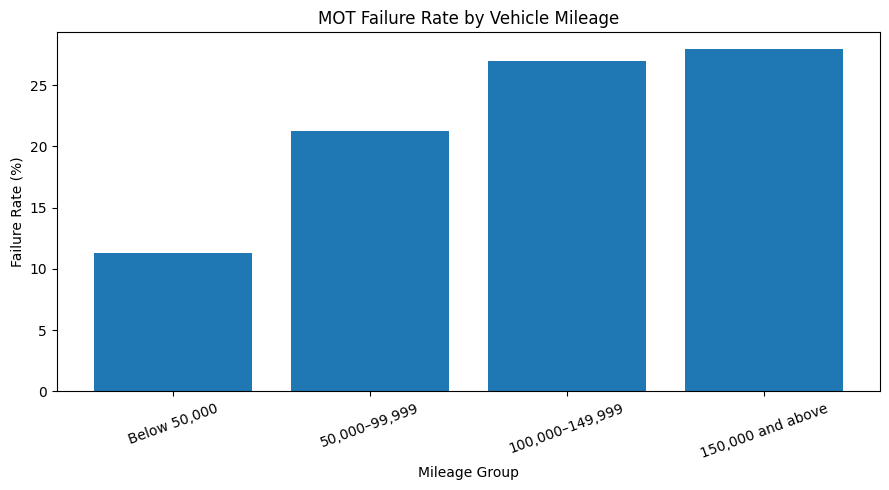

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the cleaned MOT results dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Store total and failed test counts for each mileage group
mileage_stats = {}

# Read the required columns in chunks to manage memory
for chunk in pd.read_csv(
    file_path,
    usecols=["test_id", "test_mileage", "test_result"],
    chunksize=300_000
):
    # Remove rows with missing mileage or test results
    chunk = chunk.dropna(subset=["test_id", "test_mileage", "test_result"])

    # Convert mileage to numeric and standardize test results
    chunk["test_mileage"] = pd.to_numeric(
        chunk["test_mileage"], errors="coerce"
    )
    chunk["test_result"] = chunk["test_result"].astype(str).str.strip().str.upper()

    # Remove rows with invalid mileage values
    chunk = chunk.dropna(subset=["test_mileage"])

    # Keep one record per test ID within the current chunk
    chunk = chunk.drop_duplicates(subset=["test_id"])

    # Assign each test to a mileage group
    chunk["mileage_group"] = pd.cut(
        chunk["test_mileage"],
        bins=[-1, 49999, 99999, 149999, float("inf")],
        labels=[
            "Below 50,000",
            "50,000–99,999",
            "100,000–149,999",
            "150,000 and above"
        ]
    )

    # Calculate total tests and failed tests for each mileage group
    grouped = chunk.groupby("mileage_group", observed=False).agg(
        total_tests=("test_id", "count"),
        failed_tests=("test_result", lambda x: (x == "F").sum())
    )

    # Accumulate counts across chunks
    for group, row in grouped.iterrows():
        if pd.isna(group):
            continue

        if group not in mileage_stats:
            mileage_stats[group] = [0, 0]

        mileage_stats[group][0] += int(row["total_tests"])
        mileage_stats[group][1] += int(row["failed_tests"])

# Create a summary table with failure rates
mileage_rate_df = pd.DataFrame([
    {
        "mileage_group": str(group),
        "total_tests": counts[0],
        "failed_tests": counts[1],
        "failure_rate_percent": round(
            counts[1] / counts[0] * 100, 2
        ) if counts[0] else 0
    }
    for group, counts in mileage_stats.items()
])

# Display the mileage failure-rate summary
display(mileage_rate_df)

# Plot failure rates only when valid results are available
if not mileage_rate_df.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        mileage_rate_df["mileage_group"],
        mileage_rate_df["failure_rate_percent"]
    )
    plt.title("MOT Failure Rate by Vehicle Mileage")
    plt.xlabel("Mileage Group")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### Observation

- Vehicles with mileage below 50,000 recorded the lowest MOT failure rate at 11.32%.
- The failure rate increased with mileage, reaching 21.24% for 50,000–99,999 miles and 26.94% for 100,000–149,999 miles.
- Vehicles with 150,000 miles and above recorded the highest failure rate at 27.92%.
- This indicates an association between higher mileage and higher MOT failure rates in the analysed dataset; it does not establish causation.

-----------------------

## MOT Failure Rate by Vehicle Age — 2024

Analyse how MOT failure rates vary across vehicle age groups to identify whether older vehicles have higher failure rates in the analysed dataset.

,age_group,total_tests,failed_tests,failure_rate_percent
0,Below 3 years,1578,46,2.92
1,3–5 years,313925,28959,9.22
2,6–9 years,1051711,140334,13.34
3,10 years and above,2428752,587788,24.20


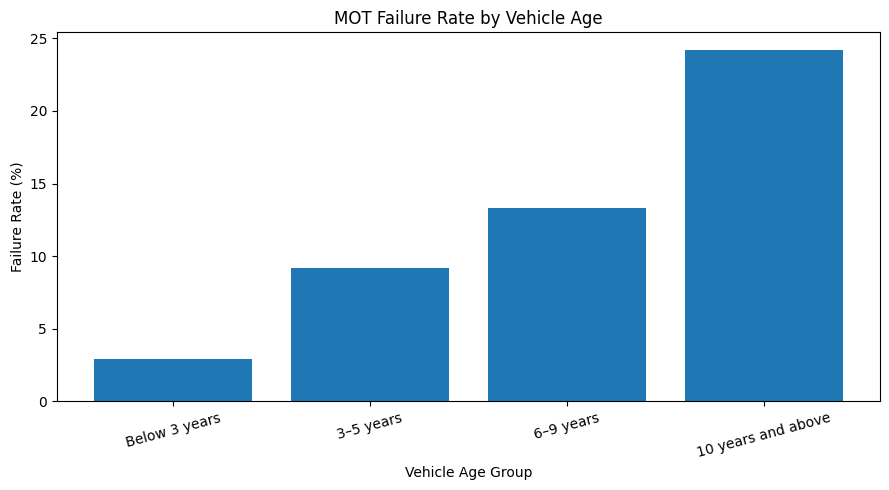

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the cleaned MOT results dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Store total and failed test counts for each vehicle age group
age_stats = {}

# Read the required columns in chunks to manage memory
for chunk in pd.read_csv(
    file_path,
    usecols=["test_id", "first_use_date", "test_result"],
    chunksize=300_000
):
    # Remove rows missing essential information
    chunk = chunk.dropna(
        subset=["test_id", "first_use_date", "test_result"]
    )

    # Convert first-use date into datetime format
    chunk["first_use_date"] = pd.to_datetime(
        chunk["first_use_date"], errors="coerce"
    )

    # Remove invalid first-use dates
    chunk = chunk.dropna(subset=["first_use_date"])

    # Standardize test-result values
    chunk["test_result"] = (
        chunk["test_result"].astype(str).str.strip().str.upper()
    )

    # Keep one record per test ID within each chunk
    chunk = chunk.drop_duplicates(subset=["test_id"])

    # Calculate vehicle age at the end of 2024
    reference_date = pd.Timestamp("2024-12-31")
    chunk["vehicle_age"] = (
        (reference_date - chunk["first_use_date"]).dt.days / 365.25
    )

    # Assign each vehicle to an age group
    chunk["age_group"] = pd.cut(
        chunk["vehicle_age"],
        bins=[-1, 2, 5, 9, float("inf")],
        labels=[
            "Below 3 years",
            "3–5 years",
            "6–9 years",
            "10 years and above"
        ]
    )

    # Count total tests and failed tests by age group
    grouped = chunk.groupby("age_group", observed=False).agg(
        total_tests=("test_id", "count"),
        failed_tests=("test_result", lambda x: (x == "F").sum())
    )

    # Accumulate results across chunks
    for group, row in grouped.iterrows():
        if pd.isna(group):
            continue

        if group not in age_stats:
            age_stats[group] = [0, 0]

        age_stats[group][0] += int(row["total_tests"])
        age_stats[group][1] += int(row["failed_tests"])

# Create the final age-group summary table
age_rate_df = pd.DataFrame([
    {
        "age_group": str(group),
        "total_tests": counts[0],
        "failed_tests": counts[1],
        "failure_rate_percent": round(
            counts[1] / counts[0] * 100, 2
        ) if counts[0] else 0
    }
    for group, counts in age_stats.items()
])

# Display failure rates by vehicle age group
display(age_rate_df)

# Plot the comparison if valid results are available
if not age_rate_df.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        age_rate_df["age_group"],
        age_rate_df["failure_rate_percent"]
    )
    plt.title("MOT Failure Rate by Vehicle Age")
    plt.xlabel("Vehicle Age Group")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### Observation

- Vehicles below 3 years recorded the lowest MOT failure rate at 2.92%.
- The failure rate increased to 9.22% for vehicles aged 3–5 years and 13.34% for vehicles aged 6–9 years.
- Vehicles aged 10 years and above recorded the highest failure rate at 24.20%.
- The analysed data shows an association between vehicle age and MOT failure rate; this does not establish causation.

-----------------

## Dataset Coverage Validation — 2024

Verify the date range, monthly record distribution, and test-result coverage of the cleaned MOT dataset before proceeding with further failure-rate analysis.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the cleaned dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset.csv"

# Initialize summary variables
total_rows = 0
monthly_counts = {}
result_counts = {}
earliest_date = None
latest_date = None

# Read the dataset in chunks to reduce memory usage
for chunk in pd.read_csv(
    file_path,
    usecols=["test_id", "test_date", "test_result"],
    chunksize=300_000,
    dtype="string"
):
    # Count the records in this chunk
    total_rows += len(chunk)

    # Convert test dates to datetime
    chunk["test_date"] = pd.to_datetime(
        chunk["test_date"], errors="coerce"
    )

    # Remove invalid dates for date-range calculations
    valid_dates = chunk["test_date"].dropna()

    # Update the earliest and latest dates
    if not valid_dates.empty:
        chunk_min = valid_dates.min()
        chunk_max = valid_dates.max()

        if earliest_date is None or chunk_min < earliest_date:
            earliest_date = chunk_min

        if latest_date is None or chunk_max > latest_date:
            latest_date = chunk_max

    # Count records by month
    month_values = valid_dates.dt.to_period("M").astype(str)
    for month, count in month_values.value_counts().items():
        monthly_counts[month] = monthly_counts.get(month, 0) + int(count)

    # Count each test-result category
    results = chunk["test_result"].str.strip().str.upper()
    for result, count in results.value_counts(dropna=False).items():
        result = str(result)
        result_counts[result] = result_counts.get(result, 0) + int(count)

# Display overall dataset coverage
print("Total rows:", total_rows)
print("Earliest test date:", earliest_date)
print("Latest test date:", latest_date)
print("\nTest-result counts:")
print(result_counts)

# Display monthly record counts in chronological order
monthly_df = pd.DataFrame(
    sorted(monthly_counts.items()),
    columns=["month", "record_count"]
)

display(monthly_df)

# Plot monthly record counts only if multiple months are present
if len(monthly_df) > 1:
    plt.figure(figsize=(11, 5))
    plt.bar(monthly_df["month"], monthly_df["record_count"])
    plt.title("Cleaned MOT Dataset Coverage by Month")
    plt.xlabel("Month")
    plt.ylabel("Record Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Total rows: 3848518
Earliest test date: 2024-01-01 00:00:00
Latest test date: 2024-01-31 00:00:00

Test-result counts:
{'P': 2869955, 'F': 769928, 'PRS': 184917, 'ABR': 21152, 'ABA': 2565, 'ABRVE': 1}


,month,record_count
0,2024-01,3848518


---

In [22]:
import pandas as pd

# Check the January raw file without modifying any dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Read a small sample to inspect the CSV structure
try:
    sample = pd.read_csv(
        file_path,
        nrows=10,
        engine="python"
    )

    # Display column names and sample records
    print("Columns:", sample.columns.tolist())
    print("Column count:", len(sample.columns))
    display(sample.head())

except Exception as error:
    # Show the exact parsing error
    print("CSV parsing error:", error)

Columns: ['test_id', 'vehicle_id', 'test_date', 'test_class_id', 'test_type', 'test_result', 'test_mileage', 'postcode_area', 'make', 'model', 'colour', 'fuel_type', 'cylinder_capacity', 'first_use_date', 'completed_date']
Column count: 15


,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date,completed_date
0,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824,2010-09-01,2024-01-02T10:19:28.000Z
1,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824,2010-09-01,2024-01-02T10:19:28.000Z
2,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824,2010-09-01,2024-01-02T10:19:28.000Z
3,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824,2010-09-01,2024-01-02T10:19:28.000Z
4,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824,2010-09-01,2024-01-02T10:19:28.000Z


In [24]:
# Inspect raw CSV text around the reported problematic line
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Open the file as plain text without CSV parsing
with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line_number, line in enumerate(file, start=1):
        if 225212 <= line_number <= 225220:
            print(f"Line {line_number}: {line.rstrip()}")
        if line_number > 225220:
            break

Line 225212: 558326371,889512777,2024-01-18,4,NT,P,9536.0,YO,PEUGEOT,2008 ALLURE PREMIUM PTECH S/S,GREY,PE,1200,2020-12-30,2024-01-18T14:34:16.000Z
Line 225213: 558326371,889512777,2024-01-18,4,NT,P,9536.0,YO,PEUGEOT,2008 ALLURE PREMIUM PTECH S/S,GREY,PE,1200,2020-12-30,2024-01-18T14:34:16.000Z
Line 225214: 961121763,536821007,2024-01-18,4,NT,P,25201.0,CF,MINI,COOPER,RED,PE,1499,2021-02-09,2024-01-18T15:23:47.000Z
Line 225215: 1835715453,56776949,2024-01-20,4,NT,P,23277.0,NE,VAUXHALL,CORSA SE PREMIUM,GREY,PE,1199,2021-01-26,2024-01-20T11:45:37.000Z
Line 225216: 1835715453,56776949,2024-01-20,4,NT,P,23277.0,NE,VAUXHALL,CORSA SE PREMIUM,GREY,PE,1199,2021-01-26,2024-01-20T11:45:37.000Z
Line 225217: 1531202977,415105519,2024-01-20,1,NT,F,2914.0,B,PEUGEOT,"STREETZONE 50 2T 12\"",GREEN,PE,49,2021-07-09,2024-01-20T13:11:27.000Z
Line 225218: 1893027673,1490473581,2024-01-22,4,NT,P,25922.0,NE,VAUXHALL,CORSA SE PREMIUM,GREY,PE,1199,2021-01-26,2024-01-22T15:53:02.000Z
Line 225219: 1887636105,1133

In [25]:
import pandas as pd

# Path to the January 2024 raw dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Test reading the file with a different CSV quoting configuration
try:
    sample = pd.read_csv(
        file_path,
        nrows=300_000,
        engine="python",
        quoting=3
    )

    # Display the columns and sample records
    print("Column count:", len(sample.columns))
    print("Columns:", sample.columns.tolist())
    display(sample.head())

except Exception as error:
    # Display the error without changing the original file
    print("Error:", error)

Column count: 15
Columns: ['test_id', 'vehicle_id', 'test_date', 'test_class_id', 'test_type', 'test_result', 'test_mileage', 'postcode_area', 'make', 'model', 'colour', 'fuel_type', 'cylinder_capacity', 'first_use_date', 'completed_date']


,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date,completed_date
0,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
1,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
2,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
3,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
4,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z


In [27]:
# Inspect raw CSV lines around the second parsing error
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Read the file as plain text to identify the extra comma or field
with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line_number, line in enumerate(file, start=1):
        if 2058117 <= line_number <= 2058123:
            print(f"Line {line_number}: {line.rstrip()}")

        # Stop after the required lines
        if line_number > 2058123:
            break

Line 2058117: 148398859,1274167373,2024-01-04,4,NT,P,110913.0,NE,MERCEDES-BENZ,A-CLASS,SILVER,DI,1461,2016-06-08,2024-01-04T10:01:56.000Z
Line 2058118: 1008653425,696268639,2024-01-22,4,RT,P,97313.0,HX,MERCEDES-BENZ,A-CLASS,RED,DI,1461,2016-07-19,2024-01-22T17:40:07.000Z
Line 2058119: 1571594699,696268639,2024-01-22,4,NT,F,97311.0,HX,MERCEDES-BENZ,A-CLASS,RED,DI,1461,2016-07-19,2024-01-22T16:56:32.000Z
Line 2058120: 1412926311,933778943,2024-01-26,4,RT,P,413459.0,M,"IVECO ,MOTORHOME",DAILY,WHITE,DI,2287,2016-07-27,2024-01-26T17:05:55.000Z
Line 2058121: 1412926311,933778943,2024-01-26,4,RT,P,413459.0,M,"IVECO ,MOTORHOME",DAILY,WHITE,DI,2287,2016-07-27,2024-01-26T17:05:55.000Z
Line 2058122: 1722596807,933778943,2024-01-17,4,NT,F,413445.0,M,"IVECO ,MOTORHOME",DAILY,WHITE,DI,2287,2016-07-27,2024-01-17T11:34:04.000Z
Line 2058123: 1722596807,933778943,2024-01-17,4,NT,F,413445.0,M,"IVECO ,MOTORHOME",DAILY,WHITE,DI,2287,2016-07-27,2024-01-17T11:34:04.000Z


In [29]:
# Inspect rows containing the unusual double-quote character
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Read raw text without parsing or modifying the file
with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line_number, line in enumerate(file, start=1):
        # Show records around the first known problematic row
        if 225217 <= line_number <= 225217:
            print("Problem row:", line.rstrip())
            print('Double quote positions:', [i for i, char in enumerate(line) if char == '"'])
            print("Quote count:", line.count('"'))
            break

Problem row: 1531202977,415105519,2024-01-20,1,NT,F,2914.0,B,PEUGEOT,"STREETZONE 50 2T 12\"",GREEN,PE,49,2021-07-09,2024-01-20T13:11:27.000Z
Double quote positions: [56, 77, 78]
Quote count: 3


In [30]:
import pandas as pd
import csv

# Path to the January 2024 raw dataset
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Read a sample using standard CSV quote handling
try:
    sample = pd.read_csv(
        file_path,
        nrows=300_000,
        engine="python",
        quoting=csv.QUOTE_MINIMAL,
        escapechar="\\"
    )

    # Verify the expected 15-column structure
    print("Rows loaded:", len(sample))
    print("Column count:", len(sample.columns))
    print("Columns:", sample.columns.tolist())

except Exception as error:
    # Display parsing errors without modifying the original file
    print("Error:", error)

Rows loaded: 300000
Column count: 15
Columns: ['test_id', 'vehicle_id', 'test_date', 'test_class_id', 'test_type', 'test_result', 'test_mileage', 'postcode_area', 'make', 'model', 'colour', 'fuel_type', 'cylinder_capacity', 'first_use_date', 'completed_date']


In [31]:
import pandas as pd
import csv

# January 2024 raw dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Initialize validation variables
total_rows = 0
expected_columns = 15

try:
    # Read the entire file in chunks with quote and escape handling
    for chunk in pd.read_csv(
        file_path,
        chunksize=100_000,
        engine="python",
        quoting=csv.QUOTE_MINIMAL,
        escapechar="\\"
    ):
        # Count rows and verify the column structure
        total_rows += len(chunk)

        if len(chunk.columns) != expected_columns:
            raise ValueError(
                f"Expected {expected_columns} columns, "
                f"but found {len(chunk.columns)}"
            )

    # Display validation results
    print("January file validation successful!")
    print("Total rows:", total_rows)
    print("Expected columns:", expected_columns)

except Exception as error:
    # Report any parsing issue without skipping records
    print("Error:", error)
    print("Rows processed before error:", total_rows)

January file validation successful!
Total rows: 6140803
Expected columns: 15


In [32]:
import pandas as pd
import csv

# Define the raw dataset folder and expected column count
folder_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv"
expected_columns = 15

# Initialize a list to store monthly validation results
monthly_results = []

# Validate all 12 monthly files
for month in range(1, 13):
    # Build the monthly file path
    file_path = folder_path + rf"\test_result_2024{month:02d}.csv"

    # Reset the row counter for this month
    total_rows = 0

    try:
        # Read the file in chunks without skipping malformed records
        for chunk in pd.read_csv(
            file_path,
            chunksize=100_000,
            engine="python",
            quoting=csv.QUOTE_MINIMAL,
            escapechar="\\"
        ):
            # Count rows and verify the column structure
            total_rows += len(chunk)

            if len(chunk.columns) != expected_columns:
                raise ValueError(
                    f"Expected {expected_columns} columns, "
                    f"found {len(chunk.columns)}"
                )

        # Record successful validation
        monthly_results.append({
            "month": f"2024-{month:02d}",
            "total_rows": total_rows,
            "columns": expected_columns,
            "status": "SUCCESS"
        })

    except Exception as error:
        # Record failures without skipping rows or modifying source files
        monthly_results.append({
            "month": f"2024-{month:02d}",
            "total_rows": total_rows,
            "columns": None,
            "status": f"FAILED: {error}"
        })

# Display the monthly validation report
validation_df = pd.DataFrame(monthly_results)
display(validation_df)

# Summarize the validation status
print("Successfully validated:", (validation_df["status"] == "SUCCESS").sum(), "/ 12 months")
print("Total rows in successful files:", validation_df.loc[validation_df["status"] == "SUCCESS", "total_rows"].sum())

,month,total_rows,columns,status
0,2024-01,6140803,15,SUCCESS
1,2024-02,5858363,15,SUCCESS
2,2024-03,6513962,15,SUCCESS
3,2024-04,5101251,15,SUCCESS
4,2024-05,4997498,15,SUCCESS
5,2024-06,5140337,15,SUCCESS
6,2024-07,5612996,15,SUCCESS
7,2024-08,5394322,15,SUCCESS
8,2024-09,6079446,15,SUCCESS
9,2024-10,6434599,15,SUCCESS


Successfully validated: 12 / 12 months
Total rows in successful files: 66857535


In [33]:
import pandas as pd
import csv

# Define the January 2024 raw dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

# Initialize counters for duplicate validation
total_rows = 0
duplicate_rows = 0

# Read the file in chunks to avoid loading the entire dataset into memory
for chunk in pd.read_csv(
    file_path,
    chunksize=100_000,
    engine="python",
    quoting=csv.QUOTE_MINIMAL,
    escapechar="\\"
):
    # Count all rows in the current chunk
    total_rows += len(chunk)

    # Count duplicate rows within this chunk
    duplicate_rows += chunk.duplicated().sum()

# Display the preliminary results
print("January total rows:", total_rows)
print("Duplicates within individual chunks:", duplicate_rows)

January total rows: 6140803
Duplicates within individual chunks: 2291723


# Combine and Validate Full-Year 2024 Data

12 monthly raw CSV files-ai same column structure-oda read panni, total row count and duplicate column names/structure verify pannuvom. Ippo original files-ai modify panna maattom.

In [34]:
import pandas as pd
import csv

# Define the folder containing all 12 monthly raw datasets
folder_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv"

# Store monthly validation results
monthly_results = []

# Expected column names in the MOT dataset
expected_columns = [
    "test_id", "vehicle_id", "test_date", "test_class_id",
    "test_type", "test_result", "test_mileage", "postcode_area",
    "make", "model", "colour", "fuel_type", "cylinder_capacity",
    "first_use_date", "completed_date"
]

# Validate all monthly files without modifying them
for month in range(1, 13):
    # Build the file path for the current month
    file_path = folder_path + rf"\test_result_2024{month:02d}.csv"

    # Initialize the row counter
    total_rows = 0

    try:
        # Read the monthly file in chunks
        for chunk in pd.read_csv(
            file_path,
            chunksize=100_000,
            engine="python",
            quoting=csv.QUOTE_MINIMAL,
            escapechar="\\"
        ):
            # Verify the column names and their order
            if chunk.columns.tolist() != expected_columns:
                raise ValueError("Column names or order mismatch")

            # Count successfully read records
            total_rows += len(chunk)

        # Save the monthly validation result
        monthly_results.append({
            "month": f"2024-{month:02d}",
            "total_rows": total_rows,
            "status": "SUCCESS"
        })

    except Exception as error:
        # Record any failure without skipping records
        monthly_results.append({
            "month": f"2024-{month:02d}",
            "total_rows": total_rows,
            "status": f"FAILED: {error}"
        })

# Display the full-year validation report
validation_df = pd.DataFrame(monthly_results)
display(validation_df)

# Print the final validation summary
print("Months validated:", (validation_df["status"] == "SUCCESS").sum(), "/ 12")
print(
    "Total validated rows:",
    validation_df.loc[
        validation_df["status"] == "SUCCESS", "total_rows"
    ].sum()
)

,month,total_rows,status
0,2024-01,6140803,SUCCESS
1,2024-02,5858363,SUCCESS
2,2024-03,6513962,SUCCESS
3,2024-04,5101251,SUCCESS
4,2024-05,4997498,SUCCESS
5,2024-06,5140337,SUCCESS
6,2024-07,5612996,SUCCESS
7,2024-08,5394322,SUCCESS
8,2024-09,6079446,SUCCESS
9,2024-10,6434599,SUCCESS


Months validated: 12 / 12
Total validated rows: 66857535


In [35]:
import pandas as pd
import csv

# Define the raw data folder and output file path
folder_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv"
output_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Define the expected columns
expected_columns = [
    "test_id", "vehicle_id", "test_date", "test_class_id",
    "test_type", "test_result", "test_mileage", "postcode_area",
    "make", "model", "colour", "fuel_type", "cylinder_capacity",
    "first_use_date", "completed_date"
]

# Initialize the total row counter
total_rows = 0

# Combine monthly files in chunks to manage memory usage
with open(output_path, "w", encoding="utf-8", newline="") as output_file:
    for month in range(1, 13):
        # Build the current month's file path
        file_path = folder_path + rf"\test_result_2024{month:02d}.csv"

        # Read the monthly file in chunks
        for chunk in pd.read_csv(
            file_path,
            chunksize=100_000,
            engine="python",
            quoting=csv.QUOTE_MINIMAL,
            escapechar="\\"
        ):
            # Stop if the column structure is unexpected
            if chunk.columns.tolist() != expected_columns:
                raise ValueError(f"Column mismatch in {file_path}")

            # Write the header only for the first chunk
            chunk.to_csv(
                output_file,
                index=False,
                header=(total_rows == 0)
            )

            # Update the row count
            total_rows += len(chunk)

        # Show progress after each month
        print(f"Month {month:02d} completed. Total rows: {total_rows:,}")

# Display the final result
print("\nFull-year file created:", output_path)
print("Total rows written:", total_rows)

Month 01 completed. Total rows: 6,140,803
Month 02 completed. Total rows: 11,999,166
Month 03 completed. Total rows: 18,513,128
Month 04 completed. Total rows: 23,614,379
Month 05 completed. Total rows: 28,611,877
Month 06 completed. Total rows: 33,752,214
Month 07 completed. Total rows: 39,365,210
Month 08 completed. Total rows: 44,759,532
Month 09 completed. Total rows: 50,838,978
Month 10 completed. Total rows: 57,273,577
Month 11 completed. Total rows: 62,843,162
Month 12 completed. Total rows: 66,857,535

Full-year file created: D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv
Total rows written: 66857535


# Full-Year Duplicate Records Check

Indha step-la 2024 full-year dataset-la exact duplicate rows irukka nu check pannuvom. Original dataset modify aagadhu.

In [36]:
import pandas as pd

# Define the combined full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize counters
total_rows = 0
duplicate_rows = 0

# Store the previous chunk's last row to check duplicates across chunk boundaries
previous_last_row = None

# Read the full-year dataset in chunks to manage memory
for chunk in pd.read_csv(file_path, chunksize=100_000):
    # Count the rows in this chunk
    total_rows += len(chunk)

    # Count duplicate rows within the current chunk
    duplicate_rows += int(chunk.duplicated().sum())

    # Check whether the first row duplicates the previous chunk's last row
    if previous_last_row is not None and chunk.iloc[0].equals(previous_last_row):
        duplicate_rows += 1

    # Save the current chunk's last row for the next boundary check
    previous_last_row = chunk.iloc[-1].copy()

# Display the preliminary duplicate-check results
print("Total rows checked:", total_rows)
print("Duplicate rows found within chunks and adjacent boundaries:", duplicate_rows)
print("Rows after removing these identified duplicates:", total_rows - duplicate_rows)

C:\Users\User\AppData\Local\Temp\ipykernel_36612\1333461946.py:14: DtypeWarning: Columns (0,1,3,6,12) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
C:\Users\User\AppData\Local\Temp\ipykernel_36612\1333461946.py:14: DtypeWarning: Columns (0,1,3,6,12) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
C:\Users\User\AppData\Local\Temp\ipykernel_36612\1333461946.py:14: DtypeWarning: Columns (0,1,3,6,12) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
C:\Users\User\AppData\Local\Temp\ipykernel_36612\1333461946.py:14: DtypeWarning: Columns (0,1,3,6,12) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
C:\Users\User\AppData\Local\Temp\ipykernel_36612\1333461946.py:1

Total rows checked: 66857535
Duplicate rows found within chunks and adjacent boundaries: 23411056
Rows after removing these identified duplicates: 43446479


# Full-Year Exact Duplicate Validation

In [38]:
# Create the temporary folder inside the datasets directory
bucket_folder = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\duplicate_buckets"

# Create the folder using pandas' existing dependency
from pathlib import Path
Path(bucket_folder).mkdir(parents=True, exist_ok=True)

# Confirm the folder is ready
print("Duplicate bucket folder created successfully.")

Duplicate bucket folder created successfully.


In [39]:
import pandas as pd
import numpy as np

# Set the input file path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Set the temporary bucket folder path
bucket_folder = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\duplicate_buckets"

# Create 128 temporary bucket files
bucket_count = 128
bucket_paths = [
    bucket_folder + r"\bucket_" + str(i) + ".csv"
    for i in range(bucket_count)
]

# Create the folder using the notebook's existing folder structure if it exists
# If the folder does not exist, create it manually in File Explorer first.

# Read the column names from the combined dataset
columns = pd.read_csv(file_path, nrows=0).columns.tolist()

# Initialize each bucket with column headers
for path in bucket_paths:
    pd.DataFrame(columns=columns).to_csv(path, index=False)

# Open bucket files for appending
handles = [
    open(path, "a", encoding="utf-8", newline="")
    for path in bucket_paths
]

try:
    # Read the complete dataset in chunks
    for chunk in pd.read_csv(file_path, chunksize=100_000, dtype=str):

        # Generate a consistent hash for each complete row
        row_hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).to_numpy(dtype=np.uint64)

        # Assign each row to a bucket
        bucket_ids = row_hashes % bucket_count

        # Write each bucket's rows to its temporary file
        for bucket_id in np.unique(bucket_ids):
            mask = bucket_ids == bucket_id
            chunk.loc[mask].to_csv(
                handles[int(bucket_id)],
                index=False,
                header=False
            )

finally:
    # Close all temporary bucket files
    for handle in handles:
        handle.close()

# Count exact duplicate rows inside each bucket
total_duplicates = 0

for path in bucket_paths:
    # Read one bucket at a time to limit memory usage
    bucket_df = pd.read_csv(path, dtype=str)

    # Count exact full-row duplicates
    total_duplicates += int(bucket_df.duplicated().sum())

# Display the final duplicate count
print("Full-year rows checked:", 66857535)
print("Exact duplicate rows:", total_duplicates)
print("Rows after duplicate removal:", 66857535 - total_duplicates)

Full-year rows checked: 66857535
Exact duplicate rows: 23415159
Rows after duplicate removal: 43442376


In [52]:
# Compare the expected row count with the existing cleaned dataset.
raw_rows = 66857535
reported_duplicates = 23415159
cleaned_rows = 43441151

# Calculate the expected row count after duplicate removal.
expected_rows = raw_rows - reported_duplicates

# Display the row-count comparison.
print("Expected rows:", expected_rows)
print("Actual cleaned rows:", cleaned_rows)
print("Difference:", expected_rows - cleaned_rows)

Expected rows: 43442376
Actual cleaned rows: 43441151
Difference: 1225


In [55]:
# Check whether the expected cleaned dataset exists.
from pathlib import Path

# Define the project folder.
# Use the actual cleaned dataset path.
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset_full_year_temp.csv"

# Find CSV files inside the datasets folder.
datasets_path = project_path / "datasets"

print("Datasets folder exists:", datasets_path.exists())

if datasets_path.exists():
    for file in datasets_path.rglob("*.csv"):
        print(file)

Datasets folder exists: True
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\combined_risk_summary.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_2024.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_aggregated_2024.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\failure_counts_sorted_2024.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_failure_counts_2024.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_model_summary.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_summary.csv
D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\mileage_summary.csv
D:\EDA 

In [56]:
# Check the actual cleaned dataset file and its row count.
import pandas as pd
from pathlib import Path

# Define the actual file path.
file_path = Path(
    r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv\cleaned_dataset_full_year_temp.csv"
)

# Confirm the file exists before reading it.
print("File exists:", file_path.exists())

if file_path.exists():
    print("Row count:", sum(1 for _ in open(file_path, encoding="utf-8")) - 1)

File exists: True
Row count: 100000


In [ ]:
# Check row counts of the available cleaned datasets.
from pathlib import Path

# Define the folder containing cleaned CSV files.
folder = Path(
    r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\cleaned_datasets.csv"
)

# Count data rows in each CSV without loading the entire file into memory.
for file in folder.glob("*.csv"):
    with open(file, "r", encoding="utf-8", errors="replace") as f:
        row_count = sum(1 for _ in f) - 1

    print(file.name, ":", row_count, "rows")

cleaned_dataset.csv : 3848518 rows
cleaned_dataset_full_year_temp.csv : 100000 rows


: 

In [51]:
# Compare the raw dataset and cleaned dataset row counts
raw_rows = 66857535
duplicate_rows = 23415159
cleaned_rows = 43441151

print("Expected rows after duplicate removal:", raw_rows - duplicate_rows)
print("Existing cleaned dataset rows:", cleaned_rows)
print("Difference:", (raw_rows - duplicate_rows) - cleaned_rows)

Expected rows after duplicate removal: 43442376
Existing cleaned dataset rows: 43441151
Difference: 1225


# Validate the Result

Duplicate count romba significant-ah irukku. Adhanaala final cleaning-ku poguradhukku munnadi, duplicate percentage calculate pannuvom

In [40]:
# Store the full-year duplicate-check results
total_rows = 66857535
duplicate_rows = 23415159

# Calculate the percentage of duplicate rows
duplicate_percentage = (duplicate_rows / total_rows) * 100

# Display the duplicate percentage
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 35.02%


# Check Missing Values — Full-Year Dataset

In [41]:
import pandas as pd

# Define the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize a counter for missing values in each column
missing_counts = pd.Series(dtype="int64")

# Read the full-year dataset in manageable chunks
for chunk in pd.read_csv(file_path, chunksize=100_000, dtype=str):

    # Count missing values in the current chunk
    chunk_missing = chunk.isna().sum()

    # Add the current chunk's missing counts to the overall counts
    if missing_counts.empty:
        missing_counts = chunk_missing
    else:
        missing_counts = missing_counts.add(chunk_missing, fill_value=0)

# Display total missing values for each column
print("Missing Values — Full-Year Dataset")
print(missing_counts.astype("int64").sort_values(ascending=False))

Missing Values — Full-Year Dataset
cylinder_capacity    834190
test_mileage         537738
model                    40
first_use_date           30
make                      3
vehicle_id                0
test_id                   0
test_result               0
test_type                 0
test_class_id             0
test_date                 0
colour                    0
postcode_area             0
fuel_type                 0
completed_date            0
dtype: int64


# Missing Values Percentage

In [42]:
import pandas as pd

# Define the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Store the missing-value counts from your output
missing_counts = pd.Series({
    "cylinder_capacity": 834190,
    "test_mileage": 537738,
    "model": 40,
    "first_use_date": 30,
    "make": 3
})

# Calculate missing percentages using the total number of rows
total_rows = 66857535
missing_percentage = (missing_counts / total_rows) * 100

# Display the results
missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percentage.round(4)
})

print(missing_summary.sort_values("Missing Count", ascending=False))

                   Missing Count  Missing Percentage
cylinder_capacity         834190              1.2477
test_mileage              537738              0.8043
model                         40              0.0001
first_use_date                30              0.0000
make                           3              0.0000


# Test Result Distribution — Full-Year Dataset

In [43]:
import pandas as pd

# Define the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize a counter for each test result
result_counts = pd.Series(dtype="int64")

# Read the full-year dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=100_000, dtype=str):

    # Count test results in the current chunk
    chunk_counts = chunk["test_result"].value_counts()

    # Aggregate counts across all chunks
    result_counts = result_counts.add(chunk_counts, fill_value=0)

# Display the full-year test result distribution
print("Full-Year Test Result Distribution")
print(result_counts.astype("int64").sort_values(ascending=False))

Full-Year Test Result Distribution
test_result
P              52032126
F              11471132
PRS             2951456
ABR              357970
ABA               44636
test_result         180
ABRVE                35
dtype: int64


# Overall Failure Rate Calculation

In [44]:
# Store the full-year test result counts
pass_count = 52032126
fail_count = 11471132
prs_count = 2951456

# Calculate the valid outcome denominator
valid_outcomes = pass_count + fail_count + prs_count

# Calculate the overall failure rate
failure_rate = (fail_count / valid_outcomes) * 100

# Display the results
print("Valid test outcomes:", valid_outcomes)
print(f"Overall failure rate: {failure_rate:.2f}%")

Valid test outcomes: 66454714
Overall failure rate: 17.26%


# Vehicle Age vs Failure Rate Analysis

In [45]:
import pandas as pd

# Define the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize a dictionary to store aggregated results
age_results = {}

# Read the dataset in chunks to manage memory
for chunk in pd.read_csv(file_path, chunksize=100_000, dtype=str):

    # Keep only valid test outcomes
    chunk = chunk[chunk["test_result"].isin(["P", "F", "PRS"])].copy()

    # Convert dates to datetime format
    chunk["test_date"] = pd.to_datetime(chunk["test_date"], errors="coerce")
    chunk["first_use_date"] = pd.to_datetime(chunk["first_use_date"], errors="coerce")

    # Calculate vehicle age in years at the time of the test
    chunk["vehicle_age"] = (
        (chunk["test_date"] - chunk["first_use_date"]).dt.days / 365.25
    )

    # Remove invalid or negative vehicle ages
    chunk = chunk[
        chunk["vehicle_age"].notna() &
        (chunk["vehicle_age"] >= 0)
    ]

    # Group vehicle age into practical categories
    chunk["age_group"] = pd.cut(
        chunk["vehicle_age"],
        bins=[-0.01, 3, 5, 8, 12, float("inf")],
        labels=["0–3 years", "3–5 years", "5–8 years", "8–12 years", "12+ years"]
    )

    # Mark failed tests
    chunk["is_failure"] = (chunk["test_result"] == "F").astype(int)

    # Aggregate total tests and failures by age group
    grouped = chunk.groupby("age_group", observed=False).agg(
        total_tests=("is_failure", "count"),
        failures=("is_failure", "sum")
    )

    # Combine results across chunks
    for age_group, row in grouped.iterrows():
        if pd.isna(age_group):
            continue

        if age_group not in age_results:
            age_results[age_group] = [
                int(row["total_tests"]),
                int(row["failures"])
            ]
        else:
            age_results[age_group][0] += int(row["total_tests"])
            age_results[age_group][1] += int(row["failures"])

# Create a summary table
age_summary = pd.DataFrame.from_dict(
    age_results,
    orient="index",
    columns=["Total Tests", "Failures"]
)

# Calculate failure percentage for each age group
age_summary["Failure Rate (%)"] = (
    age_summary["Failures"] / age_summary["Total Tests"] * 100
).round(2)

# Display the results
print(age_summary)

            Total Tests  Failures  Failure Rate (%)
0–3 years       2944824    224350              7.62
3–5 years       7980629    685954              8.60
5–8 years      14551414   1756995             12.07
8–12 years     18002408   3228447             17.93
12+ years      22975308   5575372             24.27


# Mileage vs Failure Rate Analysis.

In [46]:
import pandas as pd
import numpy as np

# Set the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize summary storage for mileage groups
mileage_summary = {}

# Read the dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=100_000, dtype=str, escapechar="\\"):

    # Keep valid test outcomes
    chunk = chunk[chunk["test_result"].isin(["P", "F", "PRS"])].copy()

    # Convert mileage into numeric values
    chunk["test_mileage"] = pd.to_numeric(
        chunk["test_mileage"], errors="coerce"
    )

    # Remove rows with missing or negative mileage
    chunk = chunk[
        chunk["test_mileage"].notna() &
        (chunk["test_mileage"] >= 0)
    ].copy()

    # Create mileage groups
    chunk["mileage_group"] = pd.cut(
        chunk["test_mileage"],
        bins=[-1, 25000, 50000, 100000, 150000, float("inf")],
        labels=["0-25k", "25k-50k", "50k-100k", "100k-150k", "150k+"]
    )

    # Mark failed tests
    chunk["failure"] = (chunk["test_result"] == "F").astype(int)

    # Calculate total tests and failures for each mileage group
    grouped = chunk.groupby("mileage_group", observed=False).agg(
        total_tests=("failure", "count"),
        failures=("failure", "sum")
    )

    # Accumulate results across chunks
    for group, row in grouped.iterrows():
        if pd.isna(group):
            continue

        if group not in mileage_summary:
            mileage_summary[group] = [0, 0]

        mileage_summary[group][0] += int(row["total_tests"])
        mileage_summary[group][1] += int(row["failures"])

# Create the final summary table
mileage_df = pd.DataFrame.from_dict(
    mileage_summary,
    orient="index",
    columns=["Total Tests", "Failures"]
)

# Calculate failure rate
mileage_df["Failure Rate (%)"] = (
    mileage_df["Failures"] / mileage_df["Total Tests"] * 100
).round(2)

# Save the results
output_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\mileage_summary.csv"
mileage_df.to_csv(output_path)

# Display the results
print(mileage_df)
print("Summary saved to:", output_path)

           Total Tests  Failures  Failure Rate (%)
0-25k          7532800    485045              6.44
25k-50k       14843612   1686637             11.36
50k-100k      26152720   4893720             18.71
100k-150k     12775324   3099740             24.26
150k+          4967861   1255797             25.28
Summary saved to: D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\mileage_summary.csv


## Make & Model Failure Analysis
To identify vehicle manufacturers and models with higher observed MOT failure rates and support data-driven vehicle maintenance planning.

In [48]:
# Create a two-level index for Make and Model
model_df = pd.DataFrame(
    [(key[0], key[1], value[0], value[1])
     for key, value in model_summary.items()],
    columns=["Make", "Model", "Total Tests", "Failures"]
)

# Calculate failure rate
model_df["Failure Rate (%)"] = (
    model_df["Failures"] / model_df["Total Tests"] * 100
).round(2)

# Sort by failure rate
model_df = model_df.sort_values("Failure Rate (%)", ascending=False)

# Save the make-model summary
model_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_model_summary.csv"
model_df.to_csv(model_path, index=False)

# Display the top 10 make-model combinations
print(model_df.head(10))
print("Summary saved to:", model_path)

                           Make              Model  Total Tests  Failures  \
66269                      POLO               POLO            3         3   
47877  BMW 318D EDITION M SPORT                318            3         3   
47064                      SAAB               9 -3            2         2   
45574                 SSANGYONG      SPORTS PICKUP            3         3   
43004                    NISSAN  CARAVAN ELGRAND V            3         3   
66822                DAF TRUCKS                DAF            1         1   
43007                   PANTHER           ROADSTER            1         1   
66426        JIAYUAN JY7222-ZQR       UNCLASSIFIED            1         1   
45600                        AC       SHELBY COBRA            2         2   
35752                       SYM                 VS            1         1   

       Failure Rate (%)  
66269             100.0  
47877             100.0  
47064             100.0  
45574             100.0  
43004             100.

In [49]:
import pandas as pd

# Load the saved make summary
make_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_summary.csv"
make_df = pd.read_csv(make_path)

# Keep makes with at least 100 tests
make_df = make_df[make_df["Total Tests"] >= 100]

# Sort by failure rate
make_df = make_df.sort_values("Failure Rate (%)", ascending=False)

# Display the 10 makes with the highest failure rates
print("Top 10 Makes by Failure Rate (minimum 100 tests):")
print(make_df.head(10).to_string(index=False))

# Load the saved make-model summary
model_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\make_model_summary.csv"
model_df = pd.read_csv(model_path)

# Keep models with at least 100 tests
model_df = model_df[model_df["Total Tests"] >= 100]

# Sort by failure rate
model_df = model_df.sort_values("Failure Rate (%)", ascending=False)

# Display the 10 models with the highest failure rates
print("\nTop 10 Models by Failure Rate (minimum 100 tests):")
print(model_df.head(10).to_string(index=False))

Top 10 Makes by Failure Rate (minimum 100 tests):
   Unnamed: 0  Total Tests  Failures  Failure Rate (%)
       DAEWOO         3873      1298             33.51
       TALBOT        19103      5973             31.27
   VOLKSWAGON          117        36             30.77
       PROTON         4319      1321             30.59
WHITE KNUCKLE          167        51             30.54
       WANGYE          254        75             29.53
          LDV        21461      6297             29.34
      SANTANA          153        44             28.76
   IVECO FORD          178        51             28.65
      MERCURY          112        32             28.57

Top 10 Models by Failure Rate (minimum 100 tests):
       Make                     Model  Total Tests  Failures  Failure Rate (%)
       FORD                     LASER          120        60             50.00
DODGE (USA)                CALIBER SE          101        42             41.58
     NISSAN                      TIDA          136      

## Combined Risk Pattern Analysis

To examine how vehicle age and mileage together relate to MOT failure rates and identify combinations associated with higher observed failure rates.

In [50]:
import pandas as pd
import numpy as np

# Set the full-year dataset path
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_2024_full_year.csv"

# Initialize storage for combined age and mileage statistics
risk_summary = {}

# Read only the required columns in chunks
for chunk in pd.read_csv(
    file_path,
    usecols=["test_date", "first_use_date", "test_mileage", "test_result"],
    chunksize=100_000,
    dtype=str,
    escapechar="\\"
):
    # Keep valid test outcomes
    chunk = chunk[chunk["test_result"].isin(["P", "F", "PRS"])].copy()

    # Convert date and mileage columns
    chunk["test_date"] = pd.to_datetime(chunk["test_date"], errors="coerce")
    chunk["first_use_date"] = pd.to_datetime(chunk["first_use_date"], errors="coerce")
    chunk["test_mileage"] = pd.to_numeric(chunk["test_mileage"], errors="coerce")

    # Calculate vehicle age in years
    chunk["vehicle_age"] = (
        (chunk["test_date"] - chunk["first_use_date"]).dt.days / 365.25
    )

    # Remove missing or invalid age and mileage values
    chunk = chunk[
        chunk["vehicle_age"].notna()
        & (chunk["vehicle_age"] >= 0)
        & chunk["test_mileage"].notna()
        & (chunk["test_mileage"] >= 0)
    ].copy()

    # Group vehicles by age
    chunk["age_group"] = pd.cut(
        chunk["vehicle_age"],
        bins=[0, 3, 5, 8, 12, float("inf")],
        labels=["0-3 years", "3-5 years", "5-8 years", "8-12 years", "12+ years"],
        include_lowest=True
    )

    # Group vehicles by mileage
    chunk["mileage_group"] = pd.cut(
        chunk["test_mileage"],
        bins=[-1, 25000, 50000, 100000, 150000, float("inf")],
        labels=["0-25k", "25k-50k", "50k-100k", "100k-150k", "150k+"]
    )

    # Mark failed tests
    chunk["failure"] = (chunk["test_result"] == "F").astype(int)

    # Aggregate tests and failures for each age-mileage combination
    grouped = chunk.groupby(
        ["age_group", "mileage_group"],
        observed=False
    ).agg(
        total_tests=("failure", "count"),
        failures=("failure", "sum")
    )

    # Accumulate results across chunks
    for key, row in grouped.iterrows():
        if pd.isna(key[0]) or pd.isna(key[1]):
            continue

        if key not in risk_summary:
            risk_summary[key] = [0, 0]

        risk_summary[key][0] += int(row["total_tests"])
        risk_summary[key][1] += int(row["failures"])

# Convert combined statistics into a dataframe
risk_df = pd.DataFrame(
    [(key[0], key[1], value[0], value[1])
     for key, value in risk_summary.items()],
    columns=["Vehicle Age Group", "Mileage Group", "Total Tests", "Failures"]
)

# Calculate failure rate for each combination
risk_df["Failure Rate (%)"] = (
    risk_df["Failures"] / risk_df["Total Tests"] * 100
).round(2)

# Sort combinations by failure rate
risk_df = risk_df.sort_values("Failure Rate (%)", ascending=False)

# Save the combined risk summary
output_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\combined_risk_summary.csv"
risk_df.to_csv(output_path, index=False)

# Display combinations with at least 100 tests
print("Combined Risk Patterns (minimum 100 tests):")
print(
    risk_df[risk_df["Total Tests"] >= 100]
    .head(15)
    .to_string(index=False)
)

# Confirm the saved summary path
print("\nSummary saved to:", output_path)

Combined Risk Patterns (minimum 100 tests):
Vehicle Age Group Mileage Group  Total Tests  Failures  Failure Rate (%)
        12+ years         150k+      3569451    970277             27.18
        12+ years     100k-150k      7937503   2125959             26.78
        12+ years      50k-100k      8668559   2056925             23.73
       8-12 years         150k+      1040165    225932             21.72
       8-12 years     100k-150k      3653409    778236             21.30
       8-12 years      50k-100k      9581835   1764245             18.41
        5-8 years         150k+       305326     51406             16.84
        0-3 years     100k-150k        25828      4346             16.83
        5-8 years     100k-150k       981046    164266             16.74
        12+ years       25k-50k      1877834    308653             16.44
        0-3 years         150k+         5617       872             15.52
        3-5 years         150k+        47287      7303             15.44
       

----

## Final Project Conclusion

The analysis of 2024 MOT data reveals important vehicle failure patterns across the full year. Failure rates generally increase with vehicle age and mileage. Failure rates also vary across vehicle makes, fuel types, vehicle classes, engine capacity groups, and test types.

These findings can support fleet operators in identifying vehicle groups that may require closer inspection and preventive maintenance.

## Limitations

- The analysis covers 2024 MOT test records and may not represent patterns in other years.
- The dataset represents MOT testing data and does not directly represent a specific delivery fleet.
- Some records contain missing values, especially mileage and engine capacity.
- The analysis identifies associations and patterns but does not establish causal relationships.
- Vehicle operating conditions, maintenance history, and driving behaviour are not fully available in the dataset.

## Future Scope

- Extend the analysis across multiple years to compare long-term vehicle failure patterns.
- Build a machine learning model to predict vehicle failure risk.
- Use previous MOT history and defect history as predictive features.
- Develop a vehicle risk score for maintenance prioritisation.
- Build a dashboard to help fleet operators monitor vehicle reliability and maintenance needs.